## Punto 4: CNN — Clasificación de imágenes (Shoe vs Sandal vs Boot)

**Dataset asignado:** *Shoe vs Sandal vs Boot Dataset (15K images)* — Kaggle (`hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images`).

**Problema:** clasificación supervisada multiclase de imágenes RGB de calzado en tres clases (`Boot`, `Sandal`, `Shoe`).

### Contenido del notebook

| Sección | Contenido | Ítem del taller |
|---|---|---|
| 0 | Configuración, información del entorno, sello de tiempo para capturas | Entregables generales |
| 1 | Descarga y carga del dataset | — |
| 2 | Análisis exploratorio (distribución, dimensiones, estadísticas RGB, desbalance, anomalías) | 4.1 |
| 3 | Formalización del problema y partición de datos | Requerimientos generales |
| 4 | Utilidades de entrenamiento y evaluación | — |
| 5 | Fase 1: Baseline MLP | 4.2 Fase 1 |
| 6 | Fase 2: Arquitecturas CNN (complejidad progresiva, BatchNorm, Data Augmentation, Dropout, Early Stopping, LR Scheduling) | 4.2 Fase 2 |
| 7 | Tabla de resultados | 4.2 |
| 8 | Análisis y justificación | 4.3 |
| 9 | Comparación final MLP vs CNN | 4.4 |
| 10 | Exportación de entregables (`.h5`, figuras, tablas) | Archivos a entregar |
| 11 | Verificación: recarga de los modelos `.h5` y predicción | Modelos listos para ejecución |

**Entorno de ejecución:** Google Colab con GPU NVIDIA T4.

### Declaración de uso de herramientas de inteligencia artificial

En cumplimiento de los requerimientos del taller, se declara el rol de las herramientas de inteligencia artificial utilizadas:

- **Herramienta utilizada:** asistente de lenguaje (Claude, Anthropic).
- **Rol de la herramienta:** generación de la estructura base del notebook, del código de preprocesamiento, entrenamiento y evaluación.
- **Decisiones tomadas por el grupo:** revisión del diseño experimental y de los hiperparámetros, ejecución y validación de los experimentos, selección de la arquitectura final con base en los resultados obtenidos e interpretación de dichos resultados.

## 0. Configuración general

En la siguiente celda se definen **todos los parámetros del experimento** en un único lugar, lo que garantiza reproducibilidad y facilita su documentación en el informe.

- `APELLIDOS`: prefijo obligatorio para la nomenclatura de archivos.
- `SEMILLA`: semilla aleatoria fija (1234), que garantiza que la partición de datos y la inicialización de pesos sean reproducibles.
- `IMG_SIZE`: las imágenes se redimensionan a 96×96 píxeles. Se eligió este tamaño como compromiso entre la conservación de detalles (correas de sandalias, caña de las botas) y el costo computacional: un MLP sobre 96×96×3 ya implica 27 648 entradas.
- Partición: 70 % entrenamiento, 15 % validación, 15 % prueba (estratificada).

In [ ]:
# ===================== PARÁMETROS DEL EXPERIMENTO =====================
APELLIDOS   = "Silva_Leon_Gomez_Tobar"   # prefijo de los archivos generados (sin tildes ni espacios)
INTEGRANTES = "Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar"  # integrantes del grupo (aparecen en los sellos de tiempo)
SEMILLA     = 3119                    # semilla fija para reproducibilidad

IMG_SIZE    = (96, 96)                # (alto, ancho) al que se redimensionan las imágenes
CANALES     = 3
BATCH_SIZE  = 64
EPOCAS_MLP  = 20                      # exigido por el taller para el baseline
EPOCAS_CNN  = 20                      # CNN 1, 2, 3 y 5
EPOCAS_MAX_CNN4 = 40                  # CNN 4 usa Early Stopping, por lo que se permite un máximo mayor
TASA_APRENDIZAJE = 1e-3
PROP_TRAIN, PROP_VAL, PROP_TEST = 0.70, 0.15, 0.15
ZONA_HORARIA = "America/Bogota"

# Carpetas de salida
DIR_MODELOS    = "modelos"
DIR_FIGURAS    = "figuras"
DIR_RESULTADOS = "resultados"

import os
for d in (DIR_MODELOS, DIR_FIGURAS, DIR_RESULTADOS):
    os.makedirs(d, exist_ok=True)
print("Configuración cargada.")

Configuración cargada.


### 0.1 Librerías y reproducibilidad

Se fijan las semillas de `random`, `numpy` y `tensorflow` para que la partición de datos y la inicialización de pesos sean reproducibles. En GPU, algunas operaciones de cuDNN no son deterministas, por lo que los resultados del entrenamiento varían entre ejecuciones aun con la misma semilla; esto se analiza como limitación en la sección 12.

In [ ]:
import sys, random, time, json, hashlib, platform, getpass, subprocess, shutil, glob
from datetime import datetime
from zoneinfo import ZoneInfo
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_fscore_support, accuracy_score)

import warnings, logging
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
logging.getLogger("absl").setLevel(logging.ERROR)

random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.random.set_seed(SEMILLA)
keras.utils.set_random_seed(SEMILLA)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 0.2 Sello de tiempo para las capturas de pantalla

El taller exige que cada `model.summary()` y cada ejecución estén respaldados por **capturas con marca de tiempo** (fecha/hora del sistema y usuario). La función `sello()` imprime un encabezado con fecha, hora, zona horaria, usuario del sistema, integrantes y máquina. Se invoca antes de cada resumen de modelo, de modo que la captura de esa celda contenga la evidencia completa.

In [ ]:
def sello(titulo=""):
    ahora = datetime.now(ZoneInfo(ZONA_HORARIA))
    linea = "=" * 78
    print(linea)
    if titulo:
        print(f"  {titulo}")
    print(f"  Fecha/hora : {ahora:%Y-%m-%d %H:%M:%S} ({ZONA_HORARIA})")
    print(f"  Usuario SO : {getpass.getuser()}   |   Integrantes: {INTEGRANTES}")
    print(f"  Máquina    : {platform.node()}   |   GPU: {bool(tf.config.list_physical_devices('GPU'))}")
    print(linea)

sello("Prueba del sello de tiempo")

  Prueba del sello de tiempo
  Fecha/hora : 2026-11-20 21:16:44 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


### 0.3 Cuadro de información del entorno de implementación

Entregable general del taller: lenguaje de programación, sistema operativo base, procesador, memoria y placa base. En Google Colab la máquina es virtual, por lo que la información de placa base corresponde a la que expone el hipervisor (si está disponible). Si el notebook se ejecuta localmente, la celda reporta el hardware real.

In [ ]:
def _leer(ruta):
    try:
        with open(ruta) as f:
            return f.read().strip()
    except Exception:
        return None

def _cmd(c):
    try:
        return subprocess.check_output(c, shell=True, stderr=subprocess.DEVNULL, text=True).strip()
    except Exception:
        return None

cpu = _cmd("lscpu | grep 'Model name' | sed 's/Model name:\\s*//'") or platform.processor() or "No disponible"
nucleos = os.cpu_count()
try:
    import psutil
    ram_gb = f"{psutil.virtual_memory().total / 1024**3:.1f} GB"
except Exception:
    ram_gb = "No disponible"
gpu = _cmd("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader") or "Sin GPU"
placa = " ".join(filter(None, [_leer("/sys/devices/virtual/dmi/id/board_vendor"),
                                _leer("/sys/devices/virtual/dmi/id/board_name")])) or "No disponible (máquina virtual)"
so = _cmd("cat /etc/os-release | grep PRETTY_NAME | cut -d= -f2 | tr -d '\"'") or platform.platform()

info_entorno = pd.DataFrame({
    "Elemento": ["Lenguaje de programación", "Sistema operativo", "Procesador", "Núcleos lógicos",
                 "Memoria RAM", "GPU", "Placa base", "TensorFlow / Keras", "Plataforma"],
    "Valor": [f"Python {platform.python_version()}", so, cpu, nucleos, ram_gb, gpu, placa,
              f"{tf.__version__} / {keras.__version__}",
              "Google Colab" if "google.colab" in sys.modules else "Local"],
})
info_entorno.to_csv(f"{DIR_RESULTADOS}/info_entorno.csv", index=False)
info_entorno

,Elemento,Valor
0,Lenguaje de programación,Python 3.13.16
1,Sistema operativo,Ubuntu 24.04.4 LTS
2,Procesador,Intel(R) Xeon(R) CPU @ 2.00GHz
3,Núcleos lógicos,2
4,Memoria RAM,12.7 GB
5,GPU,"Tesla T4, 15360 MiB"
6,Placa base,Google Google Compute Engine
7,TensorFlow / Keras,2.21.0 / 3.13.2
8,Plataforma,Google Colab


## 1. Descarga y carga del dataset

Se usa `kagglehub`, que descarga datasets públicos de Kaggle sin configuración adicional. Si la variable de entorno `IC_DATASET_DIR` está definida, se usa en su lugar una copia local del dataset.

La función `encontrar_raiz()` localiza automáticamente la carpeta que contiene las subcarpetas de las tres clases, sin depender del nombre exacto con el que se descomprima el dataset.

In [ ]:
CLASES_ESPERADAS = {"boot", "sandal", "shoe"}

def encontrar_raiz(base):
    # Busca la carpeta cuyas subcarpetas son exactamente las clases esperadas.
    for raiz, dirs, _ in os.walk(base):
        if CLASES_ESPERADAS.issubset({d.lower() for d in dirs}):
            return raiz
    return None

ruta_dataset = os.environ.get("IC_DATASET_DIR")
if not ruta_dataset:
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    ruta_dataset = kagglehub.dataset_download("hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images")

RAIZ = encontrar_raiz(ruta_dataset)
assert RAIZ is not None, f"No se encontraron las carpetas Boot/Sandal/Shoe dentro de {ruta_dataset}"
CLASES = sorted([d for d in os.listdir(RAIZ) if d.lower() in CLASES_ESPERADAS])
NUM_CLASES = len(CLASES)
print("Raíz del dataset:", RAIZ)
print("Clases (orden de índice):", CLASES)

Using Colab cache for faster access to the 'shoe-vs-sandal-vs-boot-dataset-15k-images' dataset.
Raíz del dataset: /kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Boot Dataset
Clases (orden de índice): ['Boot', 'Sandal', 'Shoe']


In [ ]:
EXTENSIONES = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
registros = []
for idx, clase in enumerate(CLASES):
    for f in sorted(os.listdir(os.path.join(RAIZ, clase))):
        if f.lower().endswith(EXTENSIONES):
            registros.append({"ruta": os.path.join(RAIZ, clase, f), "clase": clase, "etiqueta": idx})
df = pd.DataFrame(registros)
print(f"Total de imágenes encontradas: {len(df)}")
df.head()

Total de imágenes encontradas: 15000


,ruta,clase,etiqueta
0,/kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Bo...,Boot,0
1,/kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Bo...,Boot,0
2,/kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Bo...,Boot,0
3,/kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Bo...,Boot,0
4,/kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Bo...,Boot,0


## 2. Análisis exploratorio del dataset (4.1)

Se documentan los cuatro elementos exigidos: (a) distribución de clases, (b) dimensiones de las imágenes, (c) estadísticas de píxeles por canal RGB y (d) ratio de desbalance. Adicionalmente, se realiza **detección de anomalías** (archivos corruptos, modos de color distintos de RGB, tamaños atípicos, duplicados exactos e imágenes con brillo atípico), tal como lo piden los requerimientos generales del taller.

### 2.1 Lectura de metadatos y estadísticas de píxeles

Cada imagen se abre una sola vez y se calcula:
- tamaño (ancho × alto) y modo de color original;
- media de intensidad por canal (para detectar imágenes atípicas);
- sumas acumuladas de `x` y `x²` por canal, con las que se obtienen la **media y la desviación estándar global** por canal RGB sobre *todos los píxeles* del dataset en su resolución original: ($\sigma = \sqrt{E[x^2] - E[x]^2}$);
- hash MD5 del archivo, para detectar duplicados exactos.

Se usa un `ThreadPoolExecutor` para paralelizar la lectura de disco.

In [ ]:
def analizar_imagen(ruta):
    try:
        with open(ruta, "rb") as fh:
            contenido = fh.read()
        md5 = hashlib.md5(contenido).hexdigest()
        with Image.open(ruta) as im:
            modo = im.mode
            ancho, alto = im.size
            arr = np.asarray(im.convert("RGB"), dtype=np.float64)
        pix = arr.reshape(-1, 3)
        return dict(ok=True, md5=md5, modo=modo, ancho=ancho, alto=alto,
                    media_r=pix[:, 0].mean(), media_g=pix[:, 1].mean(), media_b=pix[:, 2].mean(),
                    suma=pix.sum(axis=0), suma2=(pix ** 2).sum(axis=0), n=pix.shape[0])
    except Exception as e:
        return dict(ok=False, error=str(e))

t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    meta = list(ex.map(analizar_imagen, df["ruta"]))
print(f"Metadatos calculados en {time.time() - t0:.1f} s")

meta_df = pd.DataFrame([{k: v for k, v in m.items() if k not in ("suma", "suma2", "n")} for m in meta])
df = pd.concat([df.reset_index(drop=True), meta_df], axis=1)
corruptas = df[~df["ok"]]
print(f"Imágenes corruptas / ilegibles: {len(corruptas)}")
if len(corruptas):
    display(corruptas[["ruta", "error"]])

Metadatos calculados en 17.3 s
Imágenes corruptas / ilegibles: 0


### 2.2 Distribución de clases y ratio de desbalance

El ratio de desbalance se define como $( r = \dfrac{n_{\text{clase mayor}}}{n_{\text{clase menor}}} )$. Un valor \( r > 1.5 \) indica un desbalance que justificaría estrategias como ponderación de clases o sobremuestreo.

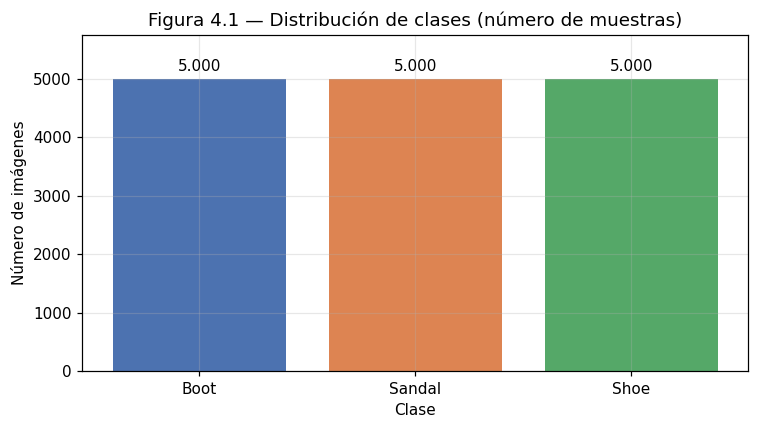

,Muestras,Porcentaje (%)
clase,,
Boot,5000,33.33
Sandal,5000,33.33
Shoe,5000,33.33


Clase mayoritaria: Boot (5000) | Clase minoritaria: Boot (5000)
Ratio de desbalance = 5000 / 5000 = 1.000 -> NO supera 1.5: dataset balanceado


In [ ]:
conteo = df[df["ok"]]["clase"].value_counts().reindex(CLASES)
ratio = conteo.max() / conteo.min()

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(conteo.index, conteo.values, color=["#4C72B0", "#DD8452", "#55A868"])
ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") for v in conteo.values], padding=3)
ax.set_title("Figura 4.1 — Distribución de clases (número de muestras)")
ax.set_xlabel("Clase"); ax.set_ylabel("Número de imágenes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout(); plt.savefig(f"{DIR_FIGURAS}/4_1_distribucion_clases.png", dpi=200); plt.show()

tabla_dist = pd.DataFrame({"Muestras": conteo, "Porcentaje (%)": (conteo / conteo.sum() * 100).round(2)})
display(tabla_dist)
print(f"Clase mayoritaria: {conteo.idxmax()} ({conteo.max()}) | Clase minoritaria: {conteo.idxmin()} ({conteo.min()})")
print(f"Ratio de desbalance = {conteo.max()} / {conteo.min()} = {ratio:.3f} -> "
      f"{'SUPERA 1.5: dataset desbalanceado' if ratio > 1.5 else 'NO supera 1.5: dataset balanceado'}")

### 2.3 Dimensiones de las imágenes (alto × ancho × canales)

In [ ]:
ok = df[df["ok"]]
dims = ok.groupby(["alto", "ancho", "modo"]).size().reset_index(name="cantidad").sort_values("cantidad", ascending=False)
dims["canales"] = dims["modo"].map(lambda m: len(Image.new(m, (1, 1)).getbands()))
print("Combinaciones de dimensiones encontradas (alto × ancho × canales):")
display(dims[["alto", "ancho", "canales", "modo", "cantidad"]].head(10))

dim_moda = dims.iloc[0]
print(f"Dimensión predominante: {dim_moda.alto} × {dim_moda.ancho} × {dim_moda.canales} "
      f"({dim_moda.cantidad / len(ok) * 100:.2f} % de las imágenes)")
print(f"Alto  -> mín {ok.alto.min()}, máx {ok.alto.max()}, media {ok.alto.mean():.1f}")
print(f"Ancho -> mín {ok.ancho.min()}, máx {ok.ancho.max()}, media {ok.ancho.mean():.1f}")
print(f"Relación de aspecto (ancho/alto) media: {(ok.ancho / ok.alto).mean():.3f}")
print(f"Tamaño de entrada usado en los modelos: {IMG_SIZE[0]} × {IMG_SIZE[1]} × {CANALES}")

Combinaciones de dimensiones encontradas (alto × ancho × canales):


,alto,ancho,canales,modo,cantidad
1,102,136,3,RGB,14998
0,102,135,3,RGB,2


Dimensión predominante: 102 × 136 × 3 (99.99 % de las imágenes)
Alto  -> mín 102, máx 102, media 102.0
Ancho -> mín 135, máx 136, media 136.0
Relación de aspecto (ancho/alto) media: 1.333
Tamaño de entrada usado en los modelos: 96 × 96 × 3


### 2.4 Estadísticas de píxeles por canal RGB

Se reportan en escala original \([0, 255]\) y normalizada \([0, 1]\) (la escala que reciben las redes tras la capa `Rescaling(1/255)`).

In [ ]:
suma  = sum(m["suma"]  for m in meta if m["ok"])
suma2 = sum(m["suma2"] for m in meta if m["ok"])
n_pix = sum(m["n"]     for m in meta if m["ok"])
media = suma / n_pix
desv  = np.sqrt(suma2 / n_pix - media ** 2)

tabla_rgb = pd.DataFrame({
    "Canal": ["R", "G", "B"],
    "Media [0-255]": media.round(3), "Desv. estándar [0-255]": desv.round(3),
    "Media [0-1]": (media / 255).round(4), "Desv. estándar [0-1]": (desv / 255).round(4),
})
tabla_rgb.to_csv(f"{DIR_RESULTADOS}/4_1_estadisticas_rgb.csv", index=False)
print(f"Total de píxeles analizados: {n_pix:,}".replace(",", "."))
display(tabla_rgb)

# Media por canal y por clase (ayuda a interpretar diferencias de color entre clases)
media_clase = ok.groupby("clase")[["media_r", "media_g", "media_b"]].mean().round(2)
media_clase.columns = ["Media R", "Media G", "Media B"]
print("Media de intensidad por clase (promedio de las medias por imagen):")
display(media_clase)

Total de píxeles analizados: 208.079.796


,Canal,Media [0-255],Desv. estándar [0-255],Media [0-1],Desv. estándar [0-1]
0,R,205.978,77.57,0.8078,0.3042
1,G,198.766,82.99,0.7795,0.3255
2,B,196.073,84.97,0.7689,0.3332


Media de intensidad por clase (promedio de las medias por imagen):


,Media R,Media G,Media B
clase,,,
Boot,206.80,199.33,196.56
Sandal,212.01,203.84,199.50
Shoe,199.12,193.13,192.16


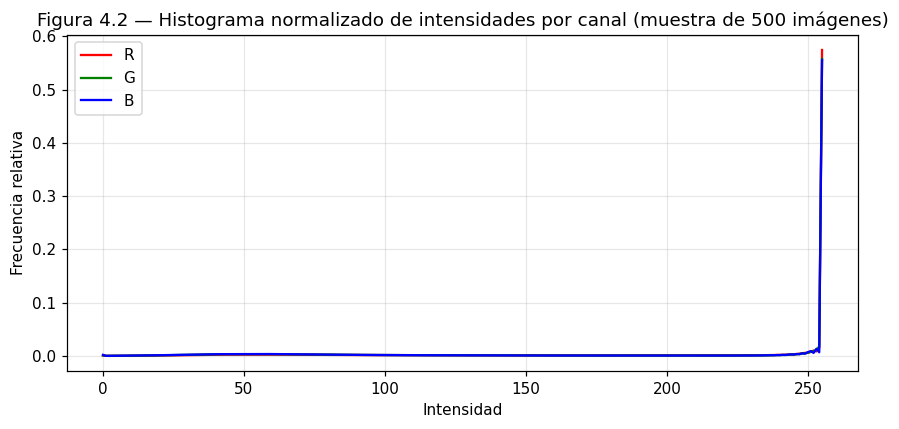

In [ ]:
# Histograma de intensidades por canal sobre una muestra de 500 imágenes
muestra = ok.sample(min(500, len(ok)), random_state=SEMILLA)
hist = np.zeros((3, 256))
for r in muestra["ruta"]:
    arr = np.asarray(Image.open(r).convert("RGB"))
    for c in range(3):
        hist[c] += np.bincount(arr[..., c].ravel(), minlength=256)

fig, ax = plt.subplots(figsize=(8, 4))
for c, col in enumerate(["red", "green", "blue"]):
    ax.plot(hist[c] / hist[c].sum(), color=col, label="RGB"[c])
ax.set_title("Figura 4.2 — Histograma normalizado de intensidades por canal (muestra de 500 imágenes)")
ax.set_xlabel("Intensidad"); ax.set_ylabel("Frecuencia relativa"); ax.legend()
plt.tight_layout(); plt.savefig(f"{DIR_FIGURAS}/4_1_histograma_rgb.png", dpi=200); plt.show()

**Interpretación:** el histograma (Figura 4.2) presenta un pico en la intensidad 255 que concentra cerca del 57 % de los píxeles de la muestra en los tres canales, mientras que el resto de intensidades tiene frecuencias casi nulas. Esto confirma que las imágenes son fotografías de catálogo sobre fondo blanco, lo que explica las medias globales altas (196 a 206 en escala 0–255) y las desviaciones estándar elevadas (78 a 85): la variación proviene del contraste entre el objeto y el fondo. En consecuencia, la información discriminante está en la **forma (silueta)** del calzado y no en el color; además, las medias por clase son muy similares entre sí (diferencias menores a 13 niveles), por lo que el color por sí solo no permite separar las clases. Esto favorece a las CNN, sensibles a bordes y patrones locales, frente al MLP.

### 2.5 Muestras visuales por clase

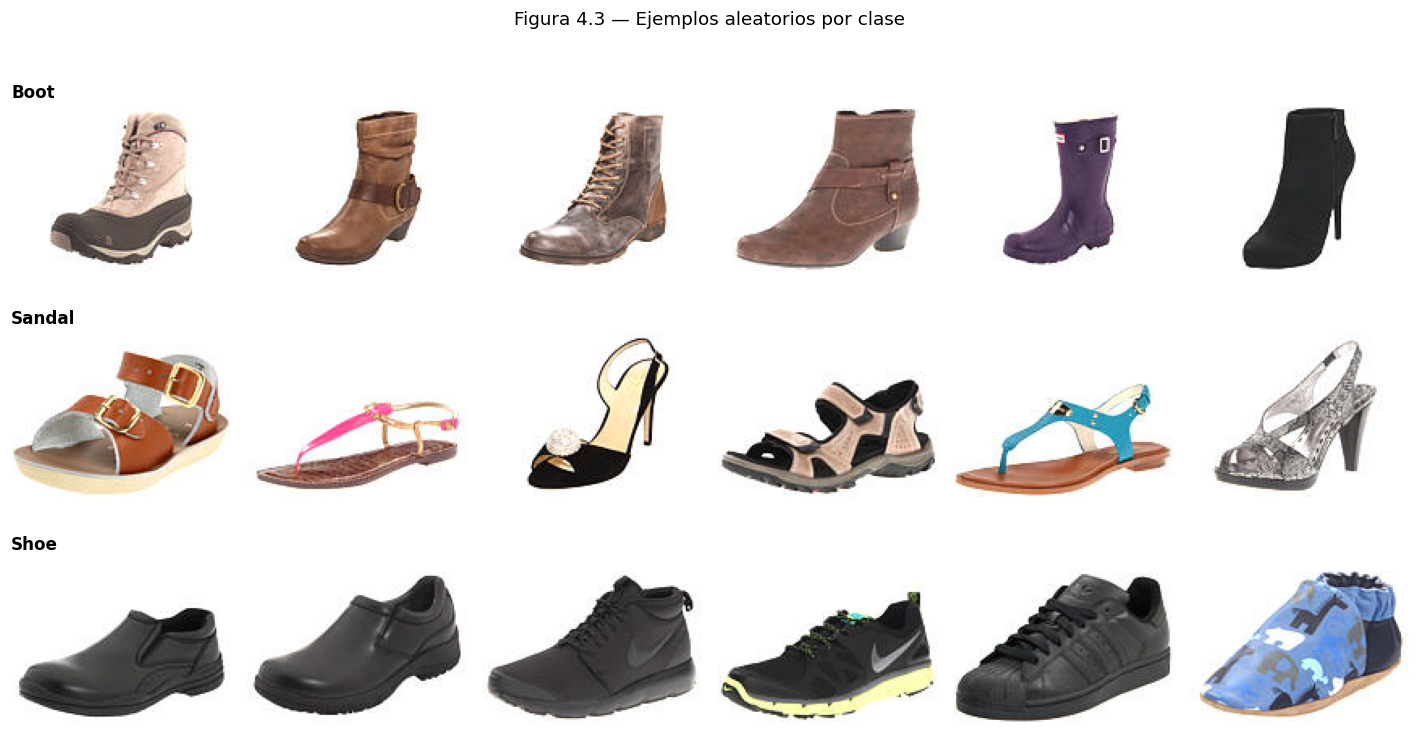

In [ ]:
fig, axes = plt.subplots(NUM_CLASES, 6, figsize=(13, 2.3 * NUM_CLASES))
for i, clase in enumerate(CLASES):
    ejemplos = ok[ok.clase == clase].sample(6, random_state=SEMILLA)
    for j, r in enumerate(ejemplos["ruta"]):
        axes[i, j].imshow(Image.open(r).convert("RGB")); axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(clase, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Figura 4.3 — Ejemplos aleatorios por clase", y=1.01)
plt.tight_layout(); plt.savefig(f"{DIR_FIGURAS}/4_1_ejemplos_clases.png", dpi=200, bbox_inches="tight"); plt.show()

### 2.6 Detección de anomalías

Se revisan cinco tipos de anomalía:
1. **Archivos corruptos** (ya calculado en 2.1).
2. **Modo de color distinto de RGB** (escala de grises, RGBA, paleta): se convierten a RGB al cargarlas.
3. **Dimensiones atípicas** respecto a la dimensión predominante.
4. **Duplicados exactos** (mismo hash MD5): podrían filtrarse entre entrenamiento y prueba e inflar artificialmente el accuracy de prueba (*data leakage*).
5. **Brillo atípico:** imágenes cuya intensidad media se aleja más de 3 desviaciones estándar de la media del dataset (|z| > 3), es decir, imágenes mucho más oscuras o más claras que el promedio.

,Anomalía,Cantidad
0,Archivos corruptos,0
1,Modo de color ≠ RGB,0
2,Dimensión distinta a la predominante,2
3,Imágenes en grupos duplicados (MD5),4
4,Grupos duplicados con clases distintas,0
5,Brillo atípico (|z| > 3),7


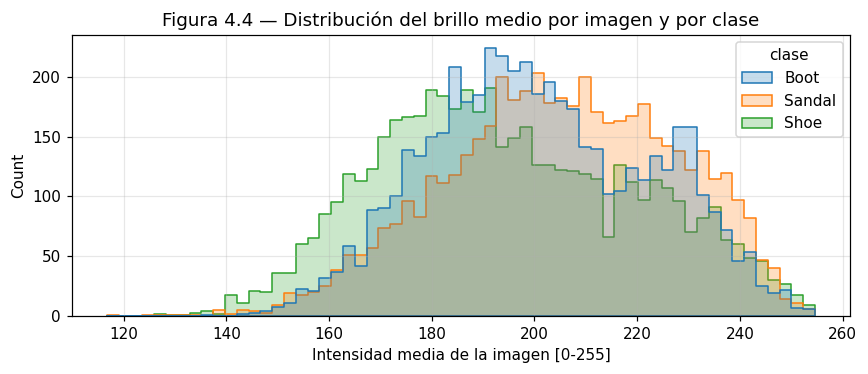

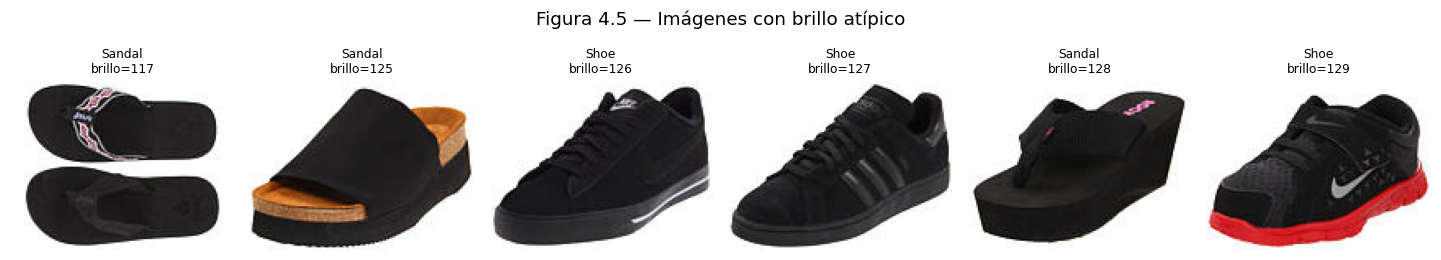

In [ ]:
ok = df[df["ok"]].copy()
ok["brillo"] = ok[["media_r", "media_g", "media_b"]].mean(axis=1)
z = (ok["brillo"] - ok["brillo"].mean()) / ok["brillo"].std()

no_rgb       = ok[ok["modo"] != "RGB"]
dim_atipica  = ok[(ok["alto"] != dim_moda.alto) | (ok["ancho"] != dim_moda.ancho)]
duplicados   = ok[ok.duplicated("md5", keep=False)].sort_values("md5")
dup_inter    = duplicados.groupby("md5")["clase"].nunique()
brillo_atip  = ok[np.abs(z) > 3]

resumen_anom = pd.DataFrame({
    "Anomalía": ["Archivos corruptos", "Modo de color ≠ RGB", "Dimensión distinta a la predominante",
                 "Imágenes en grupos duplicados (MD5)", "Grupos duplicados con clases distintas",
                 "Brillo atípico (|z| > 3)"],
    "Cantidad": [len(corruptas), len(no_rgb), len(dim_atipica), len(duplicados),
                 int((dup_inter > 1).sum()), len(brillo_atip)],
})
resumen_anom.to_csv(f"{DIR_RESULTADOS}/4_1_anomalias.csv", index=False)
display(resumen_anom)
if len(no_rgb):
    print("Modos de color encontrados:", no_rgb["modo"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=ok, x="brillo", hue="clase", bins=60, element="step", ax=ax)
ax.set_title("Figura 4.4 — Distribución del brillo medio por imagen y por clase")
ax.set_xlabel("Intensidad media de la imagen [0-255]")
plt.tight_layout(); plt.savefig(f"{DIR_FIGURAS}/4_1_brillo.png", dpi=200); plt.show()

if len(brillo_atip):
    extremos = brillo_atip.reindex(np.abs(z[brillo_atip.index]).sort_values(ascending=False).index).head(6)
    fig, axes = plt.subplots(1, len(extremos), figsize=(2.2 * len(extremos), 2.6))
    axes = np.atleast_1d(axes)
    for a, (_, f) in zip(axes, extremos.iterrows()):
        a.imshow(Image.open(f.ruta).convert("RGB")); a.axis("off")
        a.set_title(f"{f.clase}\nbrillo={f.brillo:.0f}", fontsize=8)
    plt.suptitle("Figura 4.5 — Imágenes con brillo atípico"); plt.tight_layout()
    plt.savefig(f"{DIR_FIGURAS}/4_1_anomalias_brillo.png", dpi=200); plt.show()

**Decisión de limpieza:** se eliminan (i) los archivos corruptos y (ii) los duplicados exactos, conservando una sola copia por hash, para evitar *data leakage* entre particiones. Si un mismo archivo aparece en dos clases distintas, se descartan todas sus copias, ya que su etiqueta es ambigua. Las 7 imágenes con brillo atípico **no** se eliminan: todas tienen un brillo medio inferior al del resto del dataset y corresponden a calzado negro o muy oscuro que ocupa gran parte del encuadre (Figura 4.5). Son imágenes válidas del dominio, y eliminarlas sesgaría el modelo en contra del calzado de colores oscuros.

In [ ]:
ambiguos = set(dup_inter[dup_inter > 1].index)
limpio = ok[~ok["md5"].isin(ambiguos)].drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Imágenes válidas antes de limpiar: {len(ok)}")
print(f"Eliminadas por duplicado/ambigüedad: {len(ok) - len(limpio)}")
print(f"Imágenes finales para modelado: {len(limpio)}")
print(limpio["clase"].value_counts().reindex(CLASES).to_string())

Imágenes válidas antes de limpiar: 15000
Eliminadas por duplicado/ambigüedad: 2
Imágenes finales para modelado: 14998
clase
Boot      4998
Sandal    5000
Shoe      5000


## 3. Formalización del problema y partición de datos

| Elemento | Definición |
|---|---|
| Tipo de aprendizaje | Supervisado — clasificación multiclase (3 clases mutuamente excluyentes) |
| Entrada (features) | Tensor de píxeles RGB de 96 × 96 × 3 (27 648 valores) normalizado a \([0,1]\) |
| Variable objetivo | Índice de clase \(y \in \{0,1,2\}\) → `Boot`, `Sandal`, `Shoe` |
| Función de pérdida | Entropía cruzada categórica dispersa (`sparse_categorical_crossentropy`) |
| Salida | Distribución de probabilidad mediante `softmax` |
| Optimizador | Adam (tasa de aprendizaje inicial 0.001) |
| Métricas | Accuracy, Precision, Recall y F1 (macro), matriz de confusión, curvas de pérdida |

**Partición:** 70 % entrenamiento, 15 % validación y 15 % prueba, **estratificada** por clase con `train_test_split`. El conjunto de validación se usa para monitorear el sobreajuste, para Early Stopping y para seleccionar la arquitectura; el conjunto de prueba se reserva exclusivamente para la evaluación final, de modo que la estimación de desempeño no esté sesgada por las decisiones de diseño.

In [ ]:
df_train, df_temp = train_test_split(limpio, test_size=PROP_VAL + PROP_TEST,
                                     stratify=limpio["etiqueta"], random_state=SEMILLA)
df_val, df_test = train_test_split(df_temp, test_size=PROP_TEST / (PROP_VAL + PROP_TEST),
                                   stratify=df_temp["etiqueta"], random_state=SEMILLA)

tabla_part = pd.DataFrame({
    "Entrenamiento": df_train["clase"].value_counts().reindex(CLASES),
    "Validación":    df_val["clase"].value_counts().reindex(CLASES),
    "Prueba":        df_test["clase"].value_counts().reindex(CLASES),
})
tabla_part.loc["Total"] = tabla_part.sum()
tabla_part.to_csv(f"{DIR_RESULTADOS}/particion.csv")
display(tabla_part)

,Entrenamiento,Validación,Prueba
clase,,,
Boot,3498,750,750
Sandal,3500,750,750
Shoe,3500,750,750
Total,10498,2250,2250


### 3.1 Carga de imágenes en memoria

Las imágenes se cargan una vez, se convierten a RGB y se redimensionan a 96×96 con interpolación bilineal. Se almacenan como `uint8` (≈ 415 MB para 15 000 imágenes), y la normalización a \([0,1]\) se hace **dentro de cada modelo** con una capa `Rescaling(1/255)`. Así, los archivos `.h5` guardados reciben directamente imágenes con valores 0–255, lo que simplifica su uso posterior.

Se construyen pipelines `tf.data` con barajado (solo en entrenamiento), lotes de 64 y `prefetch` para solapar la preparación de datos con el cómputo en GPU.

In [ ]:
def cargar(ruta):
    with Image.open(ruta) as im:
        return np.asarray(im.convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]), Image.BILINEAR), dtype=np.uint8)

def cargar_conjunto(d):
    with ThreadPoolExecutor(max_workers=16) as ex:
        X = np.stack(list(ex.map(cargar, d["ruta"])))
    return X, d["etiqueta"].to_numpy()

t0 = time.time()
X_train, y_train = cargar_conjunto(df_train)
X_val,   y_val   = cargar_conjunto(df_val)
X_test,  y_test  = cargar_conjunto(df_test)
print(f"Carga completada en {time.time() - t0:.1f} s")
print("X_train:", X_train.shape, X_train.dtype, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

AUTOTUNE = tf.data.AUTOTUNE
def crear_ds(X, y, barajar=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if barajar:
        ds = ds.shuffle(len(X), seed=SEMILLA, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).map(lambda a, b: (tf.cast(a, tf.float32), b)).prefetch(AUTOTUNE)

ds_train = crear_ds(X_train, y_train, barajar=True)
ds_val   = crear_ds(X_val, y_val)
ds_test  = crear_ds(X_test, y_test)
ds_train_eval = crear_ds(X_train, y_train)  # sin barajar, para evaluar accuracy de entrenamiento

Carga completada en 10.0 s
X_train: (10498, 96, 96, 3) uint8 | X_val: (2250, 96, 96, 3) | X_test: (2250, 96, 96, 3)


## 4. Utilidades de entrenamiento y evaluación

Para garantizar que **todas las arquitecturas se entrenen y evalúen exactamente con el mismo procedimiento**, se define una única función `entrenar_y_evaluar()` que:

1. Imprime el **sello de tiempo** y el `model.summary()` completo (evidencia para la captura).
2. Entrena el modelo registrando el **tiempo de cada época** con un callback propio.
3. Evalúa el modelo final en entrenamiento, validación y prueba con `model.evaluate()`. Se usa `evaluate()` (modo inferencia: sin Dropout ni Data Augmentation activos) para que el accuracy de entrenamiento sea comparable con el de validación; así, $( \text{Overfitting} = \text{Acc}_{train} - \text{Acc}_{val} )$ mide realmente la brecha de generalización.
4. Grafica las curvas de **pérdida y accuracy** (train/val) por época.
5. Calcula y grafica la **matriz de confusión** en el conjunto de prueba y el reporte de clasificación (precision, recall, F1 por clase).
6. Guarda el modelo en formato **`.h5`** con la nomenclatura exigida.

In [ ]:
class TiempoEpoca(keras.callbacks.Callback):
    # Registra la duración de cada época en segundos.
    def on_train_begin(self, logs=None):
        self.tiempos = []
    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.tiempos.append(time.time() - self._t0)

RESULTADOS = {}   # clave -> diccionario con métricas, historia, predicciones, etc.

def compilar(modelo, lr=TASA_APRENDIZAJE):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

def graficar_curvas(hist, titulo, archivo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ep = np.arange(1, len(hist["loss"]) + 1)
    axes[0].plot(ep, hist["loss"], "o-", label="Entrenamiento"); axes[0].plot(ep, hist["val_loss"], "s-", label="Validación")
    axes[0].set_title(f"Pérdida — {titulo}"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Loss"); axes[0].legend()
    axes[1].plot(ep, hist["accuracy"], "o-", label="Entrenamiento"); axes[1].plot(ep, hist["val_accuracy"], "s-", label="Validación")
    axes[1].set_title(f"Accuracy — {titulo}"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    if "learning_rate" in hist:
        ax2 = axes[0].twinx(); ax2.plot(ep, hist["learning_rate"], "k--", alpha=0.4); ax2.set_ylabel("Learning rate", alpha=0.6); ax2.grid(False)
    plt.tight_layout(); plt.savefig(archivo, dpi=200); plt.show()

def graficar_matriz(cm, titulo, archivo):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=axes[0], cbar=False)
    axes[0].set_title(f"Matriz de confusión — {titulo}"); axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("Real")
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2%", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=axes[1], cbar=False)
    axes[1].set_title("Normalizada por fila (recall por clase)"); axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Real")
    plt.tight_layout(); plt.savefig(archivo, dpi=200); plt.show()

def entrenar_y_evaluar(clave, exp, modelo, descripcion, tecnicas, epocas, callbacks_extra=()):
    sello(f"Experimento {exp} — {clave.upper()} — {descripcion}")
    modelo.summary(line_length=100)
    cb_t = TiempoEpoca()
    t0 = time.time()
    h = modelo.fit(ds_train, validation_data=ds_val, epochs=epocas,
                   callbacks=[cb_t, *callbacks_extra], verbose=2)
    t_total = time.time() - t0
    hist = {k: [float(x) for x in v] for k, v in h.history.items()}

    _, acc_tr = modelo.evaluate(ds_train_eval, verbose=0)
    _, acc_va = modelo.evaluate(ds_val, verbose=0)
    _, acc_te = modelo.evaluate(ds_test, verbose=0)
    proba = modelo.predict(ds_test, verbose=0)
    y_pred = proba.argmax(axis=1)
    cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASES))
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)

    sello(f"Resultados {clave.upper()}")
    print(f"Épocas ejecutadas: {len(hist['loss'])} | Tiempo total: {t_total:.1f} s | "
          f"Tiempo medio/época: {np.mean(cb_t.tiempos):.2f} s")
    print(f"Accuracy  train: {acc_tr*100:.2f} % | val: {acc_va*100:.2f} % | test: {acc_te*100:.2f} %")
    print(f"Overfitting (train - val): {(acc_tr - acc_va)*100:.2f} puntos porcentuales")
    print(f"Macro  P: {p:.4f} | R: {r:.4f} | F1: {f1:.4f}")
    print("\nReporte de clasificación (conjunto de prueba):")
    print(classification_report(y_test, y_pred, target_names=CLASES, digits=4, zero_division=0))

    graficar_curvas(hist, clave.upper(), f"{DIR_FIGURAS}/{clave}_curvas.png")
    graficar_matriz(cm, clave.upper(), f"{DIR_FIGURAS}/{clave}_matriz_confusion.png")

    ruta_h5 = f"{DIR_MODELOS}/{APELLIDOS}_{clave}.h5"
    modelo.save(ruta_h5, include_optimizer=False)
    print(f"Modelo guardado en: {ruta_h5} ({os.path.getsize(ruta_h5)/1024**2:.1f} MB)")

    RESULTADOS[clave] = dict(
        exp=exp, clave=clave, descripcion=descripcion, tecnicas=tecnicas,
        acc_train=acc_tr, acc_val=acc_va, acc_test=acc_te, overfitting=acc_tr - acc_va,
        params=modelo.count_params(), t_epoca=float(np.mean(cb_t.tiempos)), t_total=t_total,
        epocas=len(hist["loss"]), precision=p, recall=r, f1=f1, cm=cm, y_pred=y_pred,
        hist=hist, ruta=ruta_h5)

## 5. Fase 1 — Baseline MLP (4.2, Fase 1)

Arquitectura exigida: **Input → Flatten → Dense(128, ReLU) → Dense(64, ReLU) → Dense(3, Softmax)**, entrenada 20 épocas.

Se añade una capa `Rescaling(1/255)` inmediatamente después de la entrada; no tiene parámetros entrenables y solo normaliza los valores, por lo que no altera la arquitectura exigida.

**Hipótesis:** al aplanar la imagen, el MLP pierde la estructura espacial (vecindad entre píxeles) y debe aprender cada patrón en cada posición posible. Además, la primera capa densa concentra casi todos los parámetros (27 648 × 128 + 128 ≈ 3.5 M), por lo que se espera un modelo grande, propenso al sobreajuste y con menor accuracy que las CNN.

  Experimento 0 — BASELINE — MLP: Flatten → D128 → D64 → Softmax
  Fecha/hora : 2026-11-20 21:17:20 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


Model: "MLP_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)                       │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ normalizacion (Rescaling)                  │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ aplanado (Flatten)                         │ (None, 27648)                   │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ densa_128 (Dense)                          │ (None, 128)                     │         3,539,072 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ densa_64 (Dense)                           │ (None, 64)                      │             8,256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ salida (Dense)                             │ (None, 3)                       │               195 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 3,547,523 (13.53 MB)

 Trainable params: 3,547,523 (13.53 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
165/165 - 4s - 26ms/step - accuracy: 0.7391 - loss: 1.2718 - val_accuracy: 0.3547 - val_loss: 5.3706
Epoch 2/20
165/165 - 1s - 7ms/step - accuracy: 0.7968 - loss: 0.7412 - val_accuracy: 0.8396 - val_loss: 0.4547
Epoch 3/20
165/165 - 1s - 6ms/step - accuracy: 0.8448 - loss: 0.4264 - val_accuracy: 0.7089 - val_loss: 0.8765
Epoch 4/20
165/165 - 1s - 6ms/step - accuracy: 0.8447 - loss: 0.4265 - val_accuracy: 0.6378 - val_loss: 2.0690
Epoch 5/20
165/165 - 1s - 6ms/step - accuracy: 0.8546 - loss: 0.4053 - val_accuracy: 0.5973 - val_loss: 1.9595
Epoch 6/20
165/165 - 1s - 6ms/step - accuracy: 0.8649 - loss: 0.3801 - val_accuracy: 0.8004 - val_loss: 0.4768
Epoch 7/20
165/165 - 1s - 7ms/step - accuracy: 0.8690 - loss: 0.3385 - val_accuracy: 0.8124 - val_loss: 0.5251
Epoch 8/20
165/165 - 1s - 6ms/step - accuracy: 0.8795 - loss: 0.3189 - val_accuracy: 0.8053 - val_loss: 0.5085
Epoch 9/20
165/165 - 1s - 6ms/step - accuracy: 0.8717 - loss: 0.3421 - val_accuracy: 0.6102 - val_loss: 1.8958


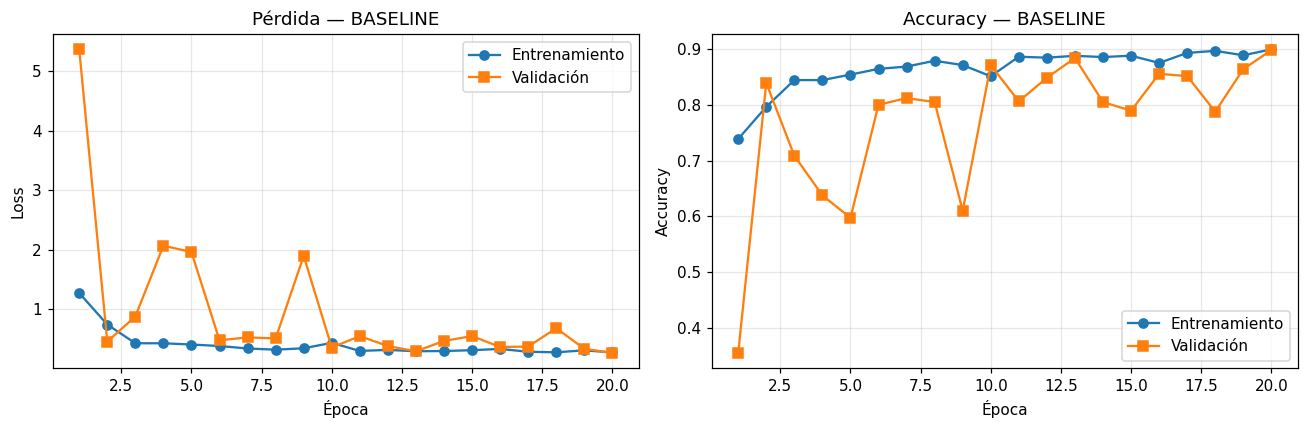

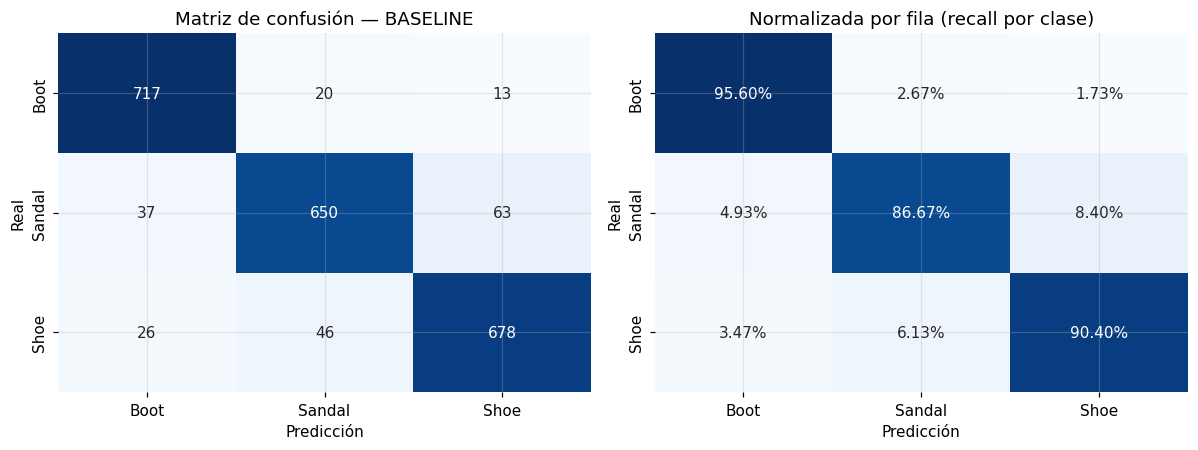

Modelo guardado en: modelos/Silva_Leon_Gomez_Tobar_baseline.h5 (13.6 MB)


In [ ]:
def construir_mlp():
    entrada = keras.Input(shape=(*IMG_SIZE, CANALES), name="entrada")
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(entrada)
    x = layers.Flatten(name="aplanado")(x)
    x = layers.Dense(128, activation="relu", name="densa_128")(x)
    x = layers.Dense(64, activation="relu", name="densa_64")(x)
    salida = layers.Dense(NUM_CLASES, activation="softmax", name="salida")(x)
    return keras.Model(entrada, salida, name="MLP_baseline")

keras.utils.set_random_seed(SEMILLA)
mlp = compilar(construir_mlp())
entrenar_y_evaluar("baseline", 0, mlp, "MLP: Flatten → D128 → D64 → Softmax",
                   "Ninguna", EPOCAS_MLP)

**Resultado observado:** la hipótesis se cumplió parcialmente. El MLP obtuvo el menor accuracy de prueba de todos los modelos (90.89 %, frente a 94.40 %–98.18 % de las CNN) con 3.5 M de parámetros, pero **no sobreajustó más que las CNN**: su brecha train−val fue de 2.32 pp, similar a la de CNN 1 (2.40 pp) y CNN 2 (2.34 pp). La diferencia está en el nivel de ajuste: el MLP solo alcanzó 92.19 % en entrenamiento, mientras que CNN 1, 2 y 3 alcanzaron al menos 99.5 %, por lo que su limitación es la capacidad de representación (subajuste), no la memorización. Su validación fue muy inestable: osciló entre 59.7 % y 89.9 % de una época a otra (después de la primera), y su peor clase fue *Sandal* (recall de 0.867, F1 de 0.887): al perder la estructura espacial, el MLP no reconoce de forma consistente las correas y aberturas que caracterizan a las sandalias.

## 6. Fase 2 — Arquitecturas CNN (4.2, Fase 2)

Se diseñaron **cinco** CNN con complejidad progresiva. Las CNN 2, 3 y 5 forman experimentos **controlados** (difieren en una sola técnica), lo que permite cuantificar el impacto aislado de cada técnica en la sección 8.2.

| Exp | Modelo | Arquitectura resumida | Técnicas | Propósito |
|---|---|---|---|---|
| 1 | CNN 1 | 2 bloques [Conv → MaxPool] (32, 64) → Flatten → D128 → D64 | Ninguna | CNN mínima, basada en el ejemplo del taller |
| 2 | CNN 2 | 3 bloques [Conv → Conv → MaxPool] (32, 64, 128) → Flatten → D128 → Dropout(0.3) → D64 | Dropout 0.3 | Mayor profundidad |
| 3 | CNN 3 | Igual a CNN 2 **+ Batch Normalization** después de cada convolución | BN, Dropout 0.3 | Aislar el efecto de BN (vs. CNN 2) |
| 4 | CNN 4 | Data Augmentation + 4 bloques [Conv-BN → Conv-BN → MaxPool] (32, 64, 128, 256) → GlobalAveragePooling → D128 → Dropout(0.5) → D64 | DA, BN, Dropout 0.5, Early Stopping, LR Scheduling | Arquitectura más completa |
| 5 | CNN 5 | Igual a CNN 3 pero con **Dropout(0.5)** | BN, Dropout 0.5 | Segundo valor de Dropout (vs. CNN 3) |

**Decisiones comunes:** filtros de 3×3 con `padding="same"` (preservan la resolución dentro del bloque), ReLU como activación, MaxPooling 2×2 para reducir la resolución a la mitad en cada bloque y duplicar el número de filtros (patrón clásico tipo VGG que mantiene el costo por capa aproximadamente constante).

**Nota sobre CNN 1:** el ejemplo del taller (Conv32 → Conv64 → MaxPool → Flatten → Dense128) con entrada de 96×96 produce un vector aplanado de 48·48·64 = 147 456 valores y ≈ 18.9 M de parámetros solo en la primera capa densa. Se añadió un MaxPool tras la primera convolución, lo que reduce el vector a 24·24·64 = 36 864 valores y el modelo a ≈ 4.7 M de parámetros, manteniendo la misma idea de dos convoluciones seguidas de capas densas.

### 6.1 CNN 1 — Arquitectura convolucional mínima

  Experimento 1 — CNN1 — 2×[Conv-Pool](32,64) → Flatten → D128 → D64
  Fecha/hora : 2026-11-20 21:17:50 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


Model: "CNN1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)                       │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ normalizacion (Rescaling)                  │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv1 (Conv2D)                          │ (None, 96, 96, 32)              │               896 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu1 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_pool (MaxPooling2D)                     │ (None, 48, 48, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv1 (Conv2D)                          │ (None, 48, 48, 64)              │            18,496 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu1 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_pool (MaxPooling2D)                     │ (None, 24, 24, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ aplanado (Flatten)                         │ (None, 36864)                   │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ densa_128 (Dense)                          │ (None, 128)                     │         4,718,720 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ densa_64 (Dense)                           │ (None, 64)                      │             8,256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ salida (Dense)                             │ (None, 3)                       │               195 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 4,746,563 (18.11 MB)

 Trainable params: 4,746,563 (18.11 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
165/165 - 8s - 47ms/step - accuracy: 0.8584 - loss: 0.3576 - val_accuracy: 0.9249 - val_loss: 0.2274
Epoch 2/20
165/165 - 3s - 20ms/step - accuracy: 0.9477 - loss: 0.1491 - val_accuracy: 0.9493 - val_loss: 0.1469
Epoch 3/20
165/165 - 3s - 20ms/step - accuracy: 0.9684 - loss: 0.0930 - val_accuracy: 0.9582 - val_loss: 0.1262
Epoch 4/20
165/165 - 3s - 19ms/step - accuracy: 0.9793 - loss: 0.0613 - val_accuracy: 0.9520 - val_loss: 0.1494
Epoch 5/20
165/165 - 3s - 19ms/step - accuracy: 0.9826 - loss: 0.0511 - val_accuracy: 0.9636 - val_loss: 0.1364
Epoch 6/20
165/165 - 3s - 20ms/step - accuracy: 0.9885 - loss: 0.0323 - val_accuracy: 0.9680 - val_loss: 0.1160
Epoch 7/20
165/165 - 3s - 20ms/step - accuracy: 0.9889 - loss: 0.0286 - val_accuracy: 0.9560 - val_loss: 0.1810
Epoch 8/20
165/165 - 3s - 19ms/step - accuracy: 0.9934 - loss: 0.0187 - val_accuracy: 0.9711 - val_loss: 0.1219
Epoch 9/20
165/165 - 3s - 19ms/step - accuracy: 0.9958 - loss: 0.0121 - val_accuracy: 0.9631 - val_loss:

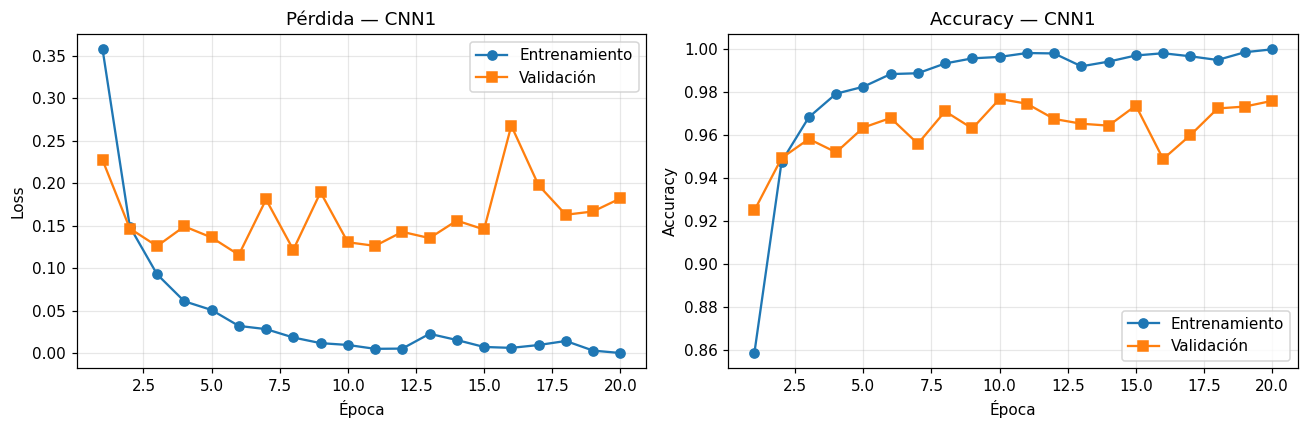

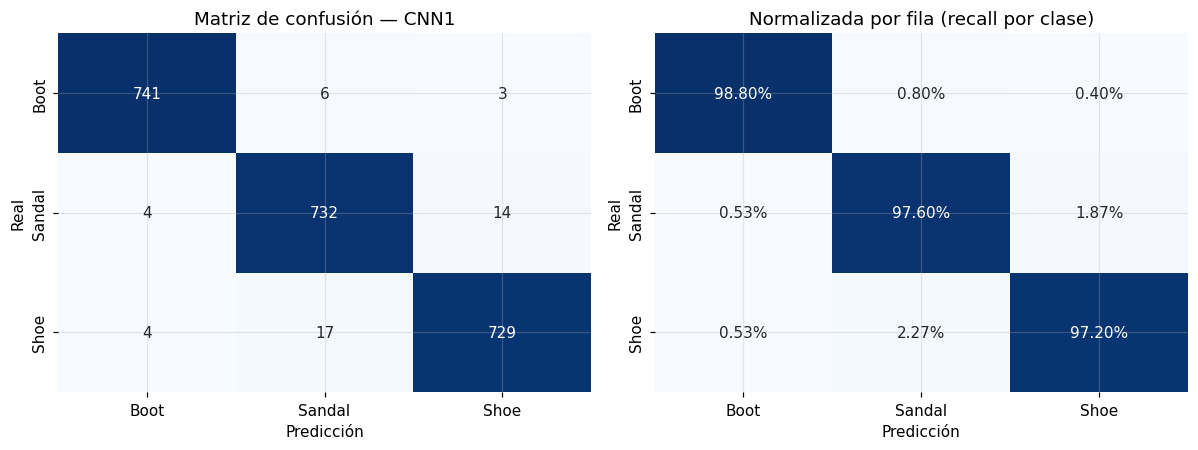

Modelo guardado en: modelos/Silva_Leon_Gomez_Tobar_cnn1.h5 (18.1 MB)


In [ ]:
def bloque_conv(x, filtros, n_conv, bn, nombre):
    for i in range(n_conv):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=not bn, name=f"{nombre}_conv{i+1}")(x)
        if bn:
            x = layers.BatchNormalization(name=f"{nombre}_bn{i+1}")(x)
        x = layers.Activation("relu", name=f"{nombre}_relu{i+1}")(x)
    return layers.MaxPooling2D(2, name=f"{nombre}_pool")(x)

def cabeza_densa(x, dropout):
    x = layers.Dense(128, activation="relu", name="densa_128")(x)
    if dropout:
        x = layers.Dropout(dropout, name=f"dropout_{dropout}")(x)
    x = layers.Dense(64, activation="relu", name="densa_64")(x)
    return layers.Dense(NUM_CLASES, activation="softmax", name="salida")(x)

def construir_cnn1():
    entrada = keras.Input(shape=(*IMG_SIZE, CANALES), name="entrada")
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(entrada)
    x = bloque_conv(x, 32, 1, False, "b1")
    x = bloque_conv(x, 64, 1, False, "b2")
    x = layers.Flatten(name="aplanado")(x)
    return keras.Model(entrada, cabeza_densa(x, 0), name="CNN1")

keras.utils.set_random_seed(SEMILLA)
cnn1 = compilar(construir_cnn1())
entrenar_y_evaluar("cnn1", 1, cnn1, "2×[Conv-Pool](32,64) → Flatten → D128 → D64",
                   "Ninguna", EPOCAS_CNN)

### 6.2 CNN 2 — Mayor profundidad (sin Batch Normalization)

Se pasa a tres bloques con **dos convoluciones por bloque**: dos convoluciones 3×3 apiladas tienen un campo receptivo de 5×5 con menos parámetros y una no linealidad adicional. El tercer bloque reduce el mapa a 12×12, por lo que el vector aplanado (12·12·128 = 18 432) es la mitad del de CNN 1. Se añade Dropout(0.3) en la cabeza densa.

  Experimento 2 — CNN2 — 3×[Conv-Conv-Pool](32,64,128) → Flatten → D128 → Drop0.3 → D64
  Fecha/hora : 2026-11-20 21:19:02 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


Model: "CNN2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)                       │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ normalizacion (Rescaling)                  │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv1 (Conv2D)                          │ (None, 96, 96, 32)              │               896 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu1 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv2 (Conv2D)                          │ (None, 96, 96, 32)              │             9,248 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu2 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_pool (MaxPooling2D)                     │ (None, 48, 48, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv1 (Conv2D)                          │ (None, 48, 48, 64)              │            18,496 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu1 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv2 (Conv2D)                          │ (None, 48, 48, 64)              │            36,928 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu2 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_pool (MaxPooling2D)                     │ (None, 24, 24, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_conv1 (Conv2D)                          │ (None, 24, 24, 128)             │            73,856 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_relu1 (Activation)                      │ (None, 24, 24, 128)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_conv2 (Conv2D)                          │ (None, 24, 24, 128)             │           147,584 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_relu2 (Activation)                      │ (None, 24, 24, 128)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_pool (MaxPooling2D)                     │ (None, 12, 12, 128)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ aplanado (Flatten)                         │ (None, 18432)                   │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ densa_128 (Dense)                          │ (None, 128)   

 Total params: 2,654,883 (10.13 MB)

 Trainable params: 2,654,883 (10.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
165/165 - 18s - 112ms/step - accuracy: 0.8364 - loss: 0.3996 - val_accuracy: 0.9391 - val_loss: 0.1734
Epoch 2/20
165/165 - 9s - 52ms/step - accuracy: 0.9474 - loss: 0.1621 - val_accuracy: 0.9604 - val_loss: 0.1095
Epoch 3/20
165/165 - 9s - 54ms/step - accuracy: 0.9655 - loss: 0.1023 - val_accuracy: 0.9653 - val_loss: 0.0960
Epoch 4/20
165/165 - 9s - 56ms/step - accuracy: 0.9664 - loss: 0.0936 - val_accuracy: 0.9676 - val_loss: 0.0885
Epoch 5/20
165/165 - 9s - 54ms/step - accuracy: 0.9782 - loss: 0.0616 - val_accuracy: 0.9684 - val_loss: 0.0902
Epoch 6/20
165/165 - 8s - 51ms/step - accuracy: 0.9841 - loss: 0.0462 - val_accuracy: 0.9773 - val_loss: 0.0672
Epoch 7/20
165/165 - 8s - 51ms/step - accuracy: 0.9888 - loss: 0.0333 - val_accuracy: 0.9707 - val_loss: 0.1011
Epoch 8/20
165/165 - 8s - 50ms/step - accuracy: 0.9905 - loss: 0.0292 - val_accuracy: 0.9711 - val_loss: 0.0896
Epoch 9/20
165/165 - 8s - 50ms/step - accuracy: 0.9895 - loss: 0.0297 - val_accuracy: 0.9813 - val_los

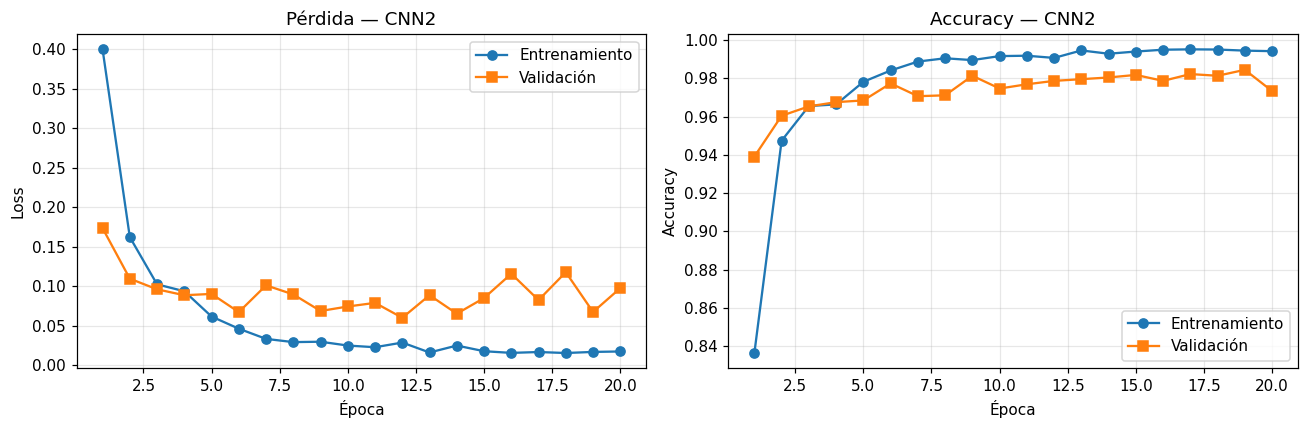

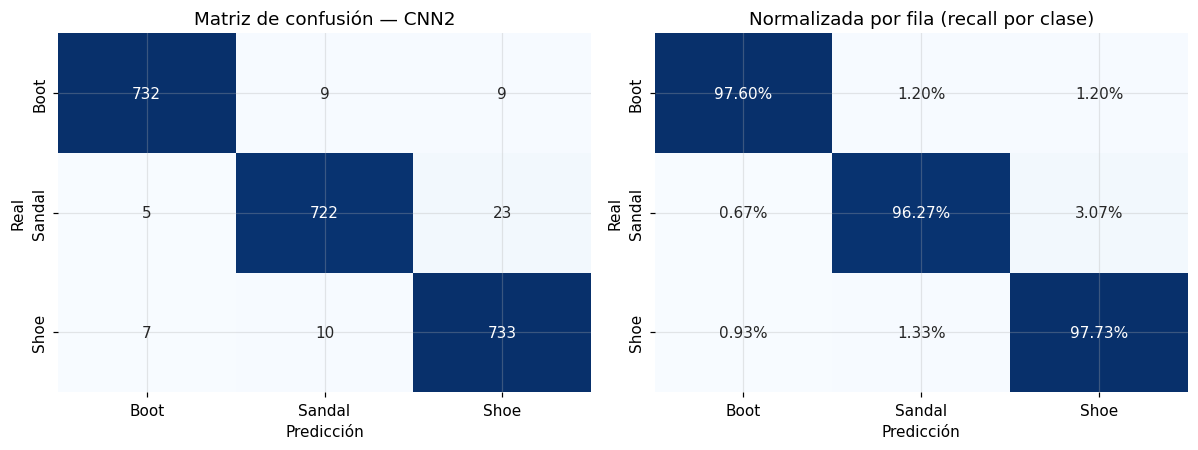

Modelo guardado en: modelos/Silva_Leon_Gomez_Tobar_cnn2.h5 (10.2 MB)


In [ ]:
def construir_cnn_3bloques(bn, dropout, nombre):
    entrada = keras.Input(shape=(*IMG_SIZE, CANALES), name="entrada")
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(entrada)
    for i, f in enumerate([32, 64, 128]):
        x = bloque_conv(x, f, 2, bn, f"b{i+1}")
    x = layers.Flatten(name="aplanado")(x)
    return keras.Model(entrada, cabeza_densa(x, dropout), name=nombre)

keras.utils.set_random_seed(SEMILLA)
cnn2 = compilar(construir_cnn_3bloques(bn=False, dropout=0.3, nombre="CNN2"))
entrenar_y_evaluar("cnn2", 2, cnn2, "3×[Conv-Conv-Pool](32,64,128) → Flatten → D128 → Drop0.3 → D64",
                   "Dropout 0.3", EPOCAS_CNN)

### 6.3 CNN 3 — CNN 2 + Batch Normalization

**Única diferencia con CNN 2:** se inserta `BatchNormalization` entre cada convolución y su activación ReLU (en ese caso la convolución no usa sesgo, porque BN ya incluye el desplazamiento β). BN normaliza las activaciones de cada lote a media 0 y varianza 1 y luego aplica una escala y un desplazamiento aprendibles. Esto estabiliza la distribución de entradas de cada capa, permite tasas de aprendizaje más altas y actúa como regularizador leve por el ruido que introducen las estadísticas de cada lote.

  Experimento 3 — CNN3 — CNN2 + BatchNorm
  Fecha/hora : 2026-11-20 21:22:09 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


Model: "CNN3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)                       │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ normalizacion (Rescaling)                  │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv1 (Conv2D)                          │ (None, 96, 96, 32)              │               864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn1 (BatchNormalization)                │ (None, 96, 96, 32)              │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu1 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv2 (Conv2D)                          │ (None, 96, 96, 32)              │             9,216 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn2 (BatchNormalization)                │ (None, 96, 96, 32)              │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu2 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_pool (MaxPooling2D)                     │ (None, 48, 48, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv1 (Conv2D)                          │ (None, 48, 48, 64)              │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn1 (BatchNormalization)                │ (None, 48, 48, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu1 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv2 (Conv2D)                          │ (None, 48, 48, 64)              │            36,864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn2 (BatchNormalization)                │ (None, 48, 48, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu2 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_pool (MaxPooling2D)                     │ (None, 24, 24, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_conv1 (Conv2D)                          │ (None, 24, 24, 128)             │            73,728 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_bn1 (BatchNormalization)                │ (None, 24, 24, 128)             │               512 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_relu1 (Activation)                      │ (None, 24, 24,

 Total params: 2,656,227 (10.13 MB)

 Trainable params: 2,655,331 (10.13 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/20
165/165 - 23s - 139ms/step - accuracy: 0.8087 - loss: 0.6508 - val_accuracy: 0.6747 - val_loss: 0.7130
Epoch 2/20
165/165 - 10s - 62ms/step - accuracy: 0.9288 - loss: 0.2039 - val_accuracy: 0.7196 - val_loss: 0.6634
Epoch 3/20
165/165 - 20s - 123ms/step - accuracy: 0.9473 - loss: 0.1574 - val_accuracy: 0.9627 - val_loss: 0.1180
Epoch 4/20
165/165 - 10s - 63ms/step - accuracy: 0.9608 - loss: 0.1153 - val_accuracy: 0.9373 - val_loss: 0.1645
Epoch 5/20
165/165 - 10s - 62ms/step - accuracy: 0.9657 - loss: 0.0968 - val_accuracy: 0.4689 - val_loss: 5.5804
Epoch 6/20
165/165 - 10s - 59ms/step - accuracy: 0.9721 - loss: 0.0848 - val_accuracy: 0.9658 - val_loss: 0.1027
Epoch 7/20
165/165 - 10s - 59ms/step - accuracy: 0.9758 - loss: 0.0723 - val_accuracy: 0.9076 - val_loss: 0.2442
Epoch 8/20
165/165 - 10s - 58ms/step - accuracy: 0.9792 - loss: 0.0602 - val_accuracy: 0.9560 - val_loss: 0.1427
Epoch 9/20
165/165 - 10s - 58ms/step - accuracy: 0.9767 - loss: 0.0680 - val_accuracy: 0.9653 

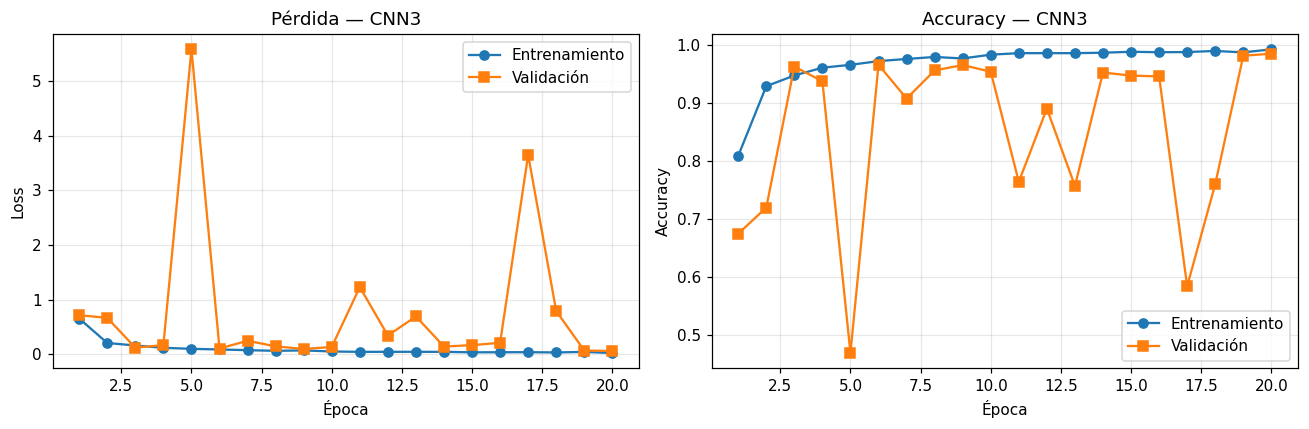

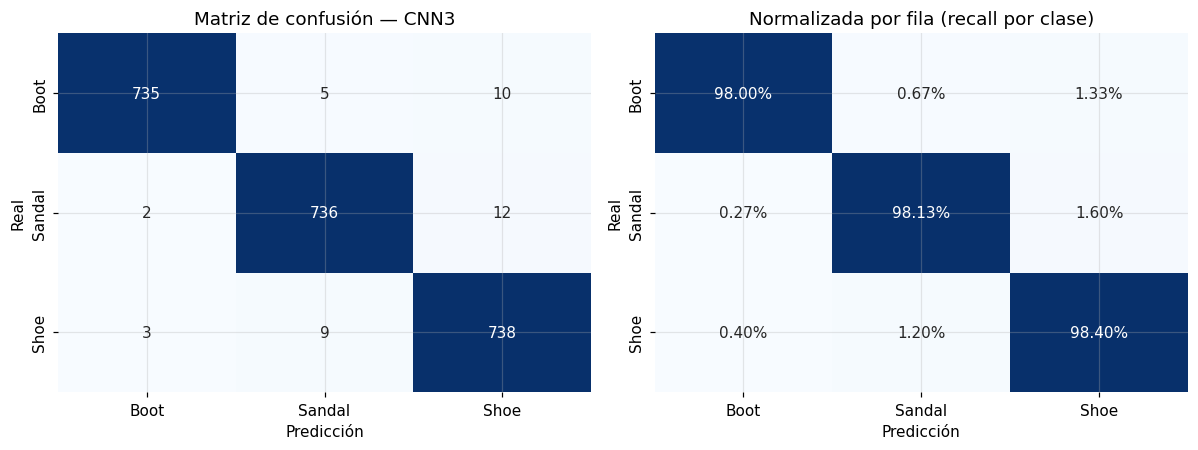

Modelo guardado en: modelos/Silva_Leon_Gomez_Tobar_cnn3.h5 (10.2 MB)


In [ ]:
keras.utils.set_random_seed(SEMILLA)
cnn3 = compilar(construir_cnn_3bloques(bn=True, dropout=0.3, nombre="CNN3"))
entrenar_y_evaluar("cnn3", 3, cnn3, "CNN2 + BatchNorm",
                   "BatchNorm, Dropout 0.3", EPOCAS_CNN)

### 6.4 CNN 4 — Arquitectura completa: Data Augmentation + BN + GAP + Dropout + Early Stopping + LR Scheduling

**Data Augmentation (técnica obligatoria).** Transformaciones aplicadas como capas de Keras al inicio del modelo; solo están activas durante el entrenamiento (en inferencia se comportan como identidad):

| Transformación | Parámetro | Justificación |
|---|---|---|
| `RandomFlip("horizontal")` | Espejo izquierda-derecha | Un zapato apuntando a la izquierda o a la derecha sigue siendo de la misma clase |
| `RandomRotation(0.05)` | ±18° | Variaciones leves de orientación de la fotografía |
| `RandomZoom(0.10)` | ±10 % | Variación del tamaño relativo del objeto en el encuadre |
| `RandomTranslation(0.10, 0.10)` | ±10 % vertical y horizontal | Objeto no siempre centrado |
| `RandomContrast(0.15)` | ±15 % | Diferencias de iluminación entre fotos |

No se aplica volteo vertical, porque un calzado invertido no corresponde a ninguna imagen realista del dominio.

**Arquitectura.** Cuatro bloques convolucionales con BN (32 → 64 → 128 → 256 filtros). En lugar de `Flatten` se usa **GlobalAveragePooling2D**, que promedia cada mapa de características (6×6×256 → 256). Esto reduce drásticamente los parámetros de la cabeza densa y obliga a la red a producir mapas de características con significado semántico.

**Regularización y control del entrenamiento (técnicas opcionales):**
- **Dropout 0.5** en la cabeza densa.
- **Early Stopping:** `monitor="val_loss"`, `patience=6`, `min_delta=1e-4`, `restore_best_weights=True`, `start_from_epoch=5`. Criterio: si la pérdida de validación no mejora durante 6 épocas consecutivas, el entrenamiento se detiene y se restauran los pesos de la mejor época. Se monitorea `val_loss` (y no `val_accuracy`) porque es una señal continua y más sensible al sobreajuste. Las primeras 5 épocas no cuentan para la paciencia, ya que con Batch Normalization la pérdida de validación suele ser inestable al inicio, mientras se estabilizan las medias móviles.
- **LR Scheduling:** `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)`: la tasa de aprendizaje se reduce a la mitad cuando la pérdida de validación se estanca 3 épocas, para afinar los pesos cerca del mínimo.

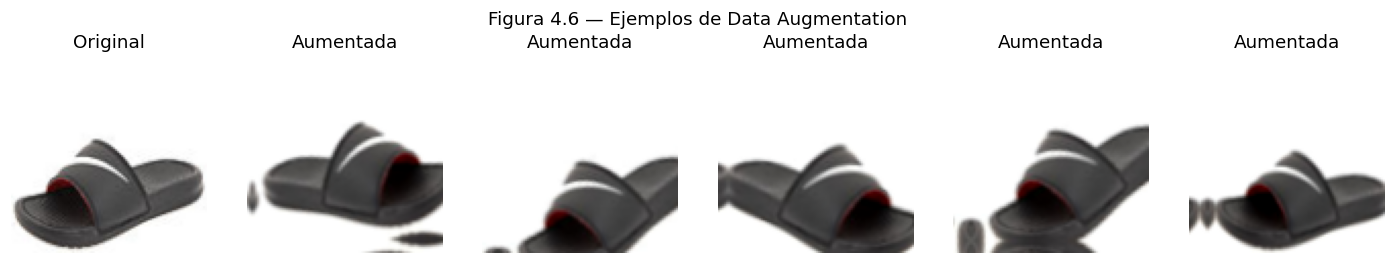

In [ ]:
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomContrast(0.15),
], name="data_augmentation")

# Visualización de las transformaciones sobre una imagen de entrenamiento
img_ej = X_train[:1].astype("float32")
fig, axes = plt.subplots(1, 6, figsize=(13, 2.4))
axes[0].imshow(img_ej[0].astype("uint8")); axes[0].set_title("Original"); axes[0].axis("off")
for a in axes[1:]:
    a.imshow(np.clip(aumento(img_ej, training=True)[0].numpy(), 0, 255).astype("uint8")); a.set_title("Aumentada"); a.axis("off")
plt.suptitle("Figura 4.6 — Ejemplos de Data Augmentation"); plt.tight_layout()
plt.savefig(f"{DIR_FIGURAS}/cnn4_data_augmentation.png", dpi=200); plt.show()

  Experimento 4 — CNN4 — DA + 4×[Conv-BN-Conv-BN-Pool](32..256) → GAP → D128 → Drop0.5 → D64
  Fecha/hora : 2026-11-20 21:26:00 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


Model: "CNN4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)                       │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ data_augmentation (Sequential)             │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ normalizacion (Rescaling)                  │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv1 (Conv2D)                          │ (None, 96, 96, 32)              │               864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn1 (BatchNormalization)                │ (None, 96, 96, 32)              │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu1 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv2 (Conv2D)                          │ (None, 96, 96, 32)              │             9,216 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn2 (BatchNormalization)                │ (None, 96, 96, 32)              │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu2 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_pool (MaxPooling2D)                     │ (None, 48, 48, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv1 (Conv2D)                          │ (None, 48, 48, 64)              │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn1 (BatchNormalization)                │ (None, 48, 48, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu1 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv2 (Conv2D)                          │ (None, 48, 48, 64)              │            36,864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn2 (BatchNormalization)                │ (None, 48, 48, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu2 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_pool (MaxPooling2D)                     │ (None, 24, 24, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_conv1 (Conv2D)                          │ (None, 24, 24, 128)             │            73,728 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_bn1 (BatchNormalization)                │ (None, 24, 24,

 Total params: 1,216,483 (4.64 MB)

 Trainable params: 1,214,563 (4.63 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/40
165/165 - 26s - 157ms/step - accuracy: 0.7289 - loss: 0.6183 - val_accuracy: 0.3338 - val_loss: 1.7034 - learning_rate: 0.0010
Epoch 2/40
165/165 - 21s - 128ms/step - accuracy: 0.8400 - loss: 0.4029 - val_accuracy: 0.5293 - val_loss: 1.4311 - learning_rate: 0.0010
Epoch 3/40
165/165 - 19s - 118ms/step - accuracy: 0.8791 - loss: 0.3265 - val_accuracy: 0.4040 - val_loss: 2.4702 - learning_rate: 0.0010
Epoch 4/40
165/165 - 19s - 117ms/step - accuracy: 0.9093 - loss: 0.2518 - val_accuracy: 0.3627 - val_loss: 4.2676 - learning_rate: 0.0010
Epoch 5/40
165/165 - 19s - 118ms/step - accuracy: 0.9241 - loss: 0.2131 - val_accuracy: 0.8493 - val_loss: 0.5463 - learning_rate: 0.0010
Epoch 6/40
165/165 - 20s - 121ms/step - accuracy: 0.9213 - loss: 0.2172 - val_accuracy: 0.4778 - val_loss: 3.5436 - learning_rate: 0.0010
Epoch 7/40
165/165 - 20s - 118ms/step - accuracy: 0.9157 - loss: 0.2372 - val_accuracy: 0.8280 - val_loss: 0.4622 - learning_rate: 0.0010
Epoch 8/40
165/165 - 20s - 123ms/s

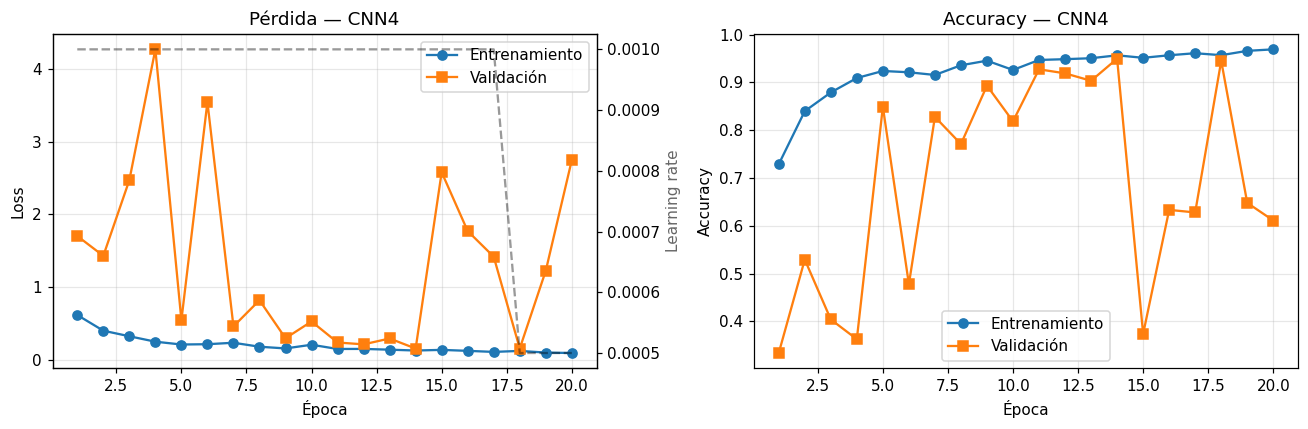

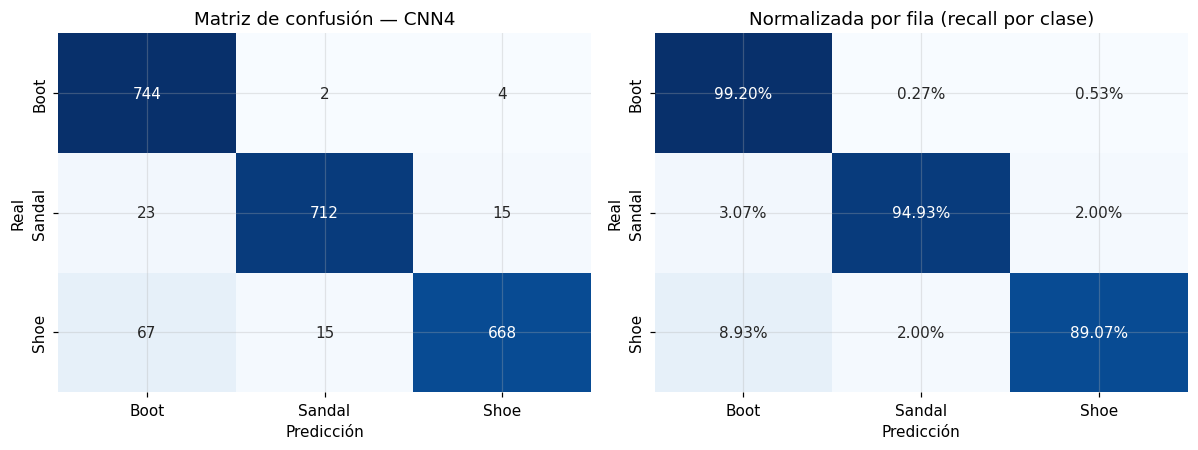

Modelo guardado en: modelos/Silva_Leon_Gomez_Tobar_cnn4.h5 (4.7 MB)
Early Stopping: mejor época = 14, épocas ejecutadas = 20


In [ ]:
def construir_cnn4():
    entrada = keras.Input(shape=(*IMG_SIZE, CANALES), name="entrada")
    x = aumento(entrada)
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(x)
    for i, f in enumerate([32, 64, 128, 256]):
        x = bloque_conv(x, f, 2, True, f"b{i+1}")
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    return keras.Model(entrada, cabeza_densa(x, 0.5), name="CNN4")

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, min_delta=1e-4,
                                           restore_best_weights=True, start_from_epoch=5, verbose=1)
lr_sched = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                             min_lr=1e-6, verbose=1)

keras.utils.set_random_seed(SEMILLA)
cnn4 = compilar(construir_cnn4())
entrenar_y_evaluar("cnn4", 4, cnn4,
                   "DA + 4×[Conv-BN-Conv-BN-Pool](32..256) → GAP → D128 → Drop0.5 → D64",
                   "DataAug, BatchNorm, Dropout 0.5, EarlyStopping, ReduceLROnPlateau",
                   EPOCAS_MAX_CNN4, callbacks_extra=[early_stop, lr_sched])
print(f"Early Stopping: mejor época = {early_stop.best_epoch + 1 if hasattr(early_stop, 'best_epoch') else 'N/D'}, "
      f"épocas ejecutadas = {RESULTADOS['cnn4']['epocas']}")

**Resultado del entrenamiento de CNN 4:** Early Stopping detuvo el entrenamiento en la **época 20** de un máximo de 40 y restauró los pesos de la **época 14**, la de menor pérdida de validación (val_acc de 95.0 %). *ReduceLROnPlateau* solo alcanzó a reducir la tasa de aprendizaje dos veces (épocas 17 y 20), de 0.001 a 0.00025. Durante todo el entrenamiento, la validación osciló fuertemente, entre 33.4 % y 95.0 %, sin llegar a estabilizarse. En consecuencia, CNN 4 obtuvo el menor desempeño de las CNN (val 94.98 %, test 94.40 %), aunque con la menor brecha de todas (−0.18 pp) y el menor número de parámetros (1.2 M). Su principal error fue clasificar zapatos como botas: la clase *Shoe* tuvo recall de 0.891 y la clase *Boot* precisión de 0.892.

La detención temprana fue prematura: con Batch Normalization, Data Augmentation y una tasa de aprendizaje todavía alta, la pérdida de validación oscila tanto que 6 épocas sin mejora no indican que el modelo haya convergido. Una paciencia mayor (10 a 12 épocas) o un `start_from_epoch` más alto habrían permitido que la reducción de la tasa de aprendizaje estabilizara el modelo.

### 6.5 CNN 5 — CNN 3 con Dropout 0.5 (segundo valor de Dropout)

**Única diferencia con CNN 3:** tasa de Dropout 0.5 en lugar de 0.3. Dropout apaga aleatoriamente una fracción *p* de neuronas en cada paso de entrenamiento, lo que impide la co-adaptación entre neuronas y equivale a entrenar un ensamble implícito de subredes. Un valor mayor regulariza más, pero puede ralentizar la convergencia o causar subajuste.

  Experimento 5 — CNN5 — CNN3 con Dropout 0.5
  Fecha/hora : 2026-11-20 21:32:47 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


Model: "CNN5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)                       │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ normalizacion (Rescaling)                  │ (None, 96, 96, 3)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv1 (Conv2D)                          │ (None, 96, 96, 32)              │               864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn1 (BatchNormalization)                │ (None, 96, 96, 32)              │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu1 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv2 (Conv2D)                          │ (None, 96, 96, 32)              │             9,216 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn2 (BatchNormalization)                │ (None, 96, 96, 32)              │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu2 (Activation)                      │ (None, 96, 96, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_pool (MaxPooling2D)                     │ (None, 48, 48, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv1 (Conv2D)                          │ (None, 48, 48, 64)              │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn1 (BatchNormalization)                │ (None, 48, 48, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu1 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv2 (Conv2D)                          │ (None, 48, 48, 64)              │            36,864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn2 (BatchNormalization)                │ (None, 48, 48, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu2 (Activation)                      │ (None, 48, 48, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_pool (MaxPooling2D)                     │ (None, 24, 24, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_conv1 (Conv2D)                          │ (None, 24, 24, 128)             │            73,728 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_bn1 (BatchNormalization)                │ (None, 24, 24, 128)             │               512 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_relu1 (Activation)                      │ (None, 24, 24,

 Total params: 2,656,227 (10.13 MB)

 Trainable params: 2,655,331 (10.13 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/20
165/165 - 23s - 139ms/step - accuracy: 0.7695 - loss: 0.7228 - val_accuracy: 0.6938 - val_loss: 0.6763
Epoch 2/20
165/165 - 10s - 60ms/step - accuracy: 0.8798 - loss: 0.3264 - val_accuracy: 0.6249 - val_loss: 0.8588
Epoch 3/20
165/165 - 11s - 64ms/step - accuracy: 0.9184 - loss: 0.2282 - val_accuracy: 0.9222 - val_loss: 0.2816
Epoch 4/20
165/165 - 11s - 64ms/step - accuracy: 0.9285 - loss: 0.2081 - val_accuracy: 0.9409 - val_loss: 0.1648
Epoch 5/20
165/165 - 10s - 60ms/step - accuracy: 0.9510 - loss: 0.1523 - val_accuracy: 0.4369 - val_loss: 6.4259
Epoch 6/20
165/165 - 10s - 58ms/step - accuracy: 0.9552 - loss: 0.1344 - val_accuracy: 0.9480 - val_loss: 0.1550
Epoch 7/20
165/165 - 9s - 57ms/step - accuracy: 0.9461 - loss: 0.1771 - val_accuracy: 0.7707 - val_loss: 0.8453
Epoch 8/20
165/165 - 9s - 57ms/step - accuracy: 0.9577 - loss: 0.1403 - val_accuracy: 0.9200 - val_loss: 0.2077
Epoch 9/20
165/165 - 10s - 58ms/step - accuracy: 0.9633 - loss: 0.1128 - val_accuracy: 0.9062 - v

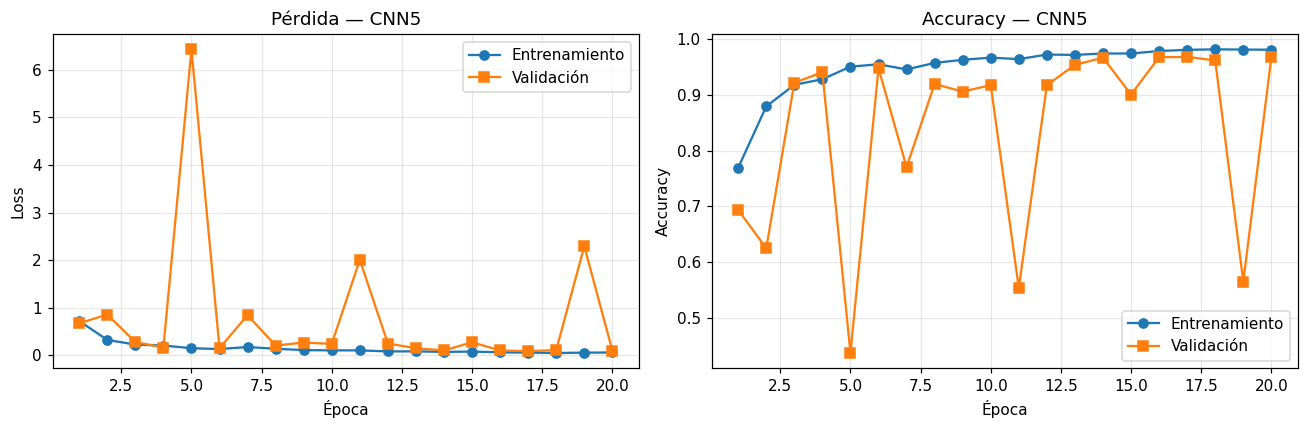

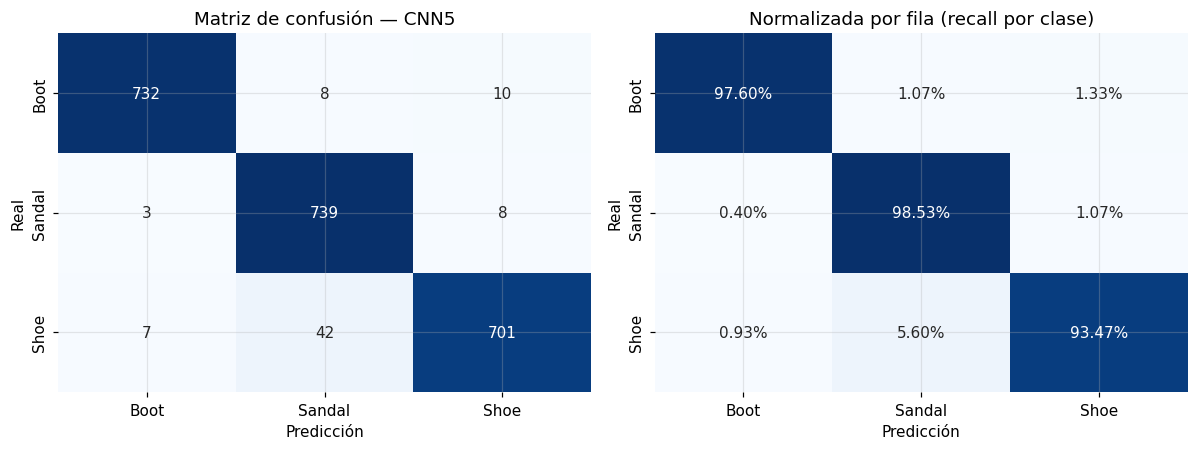

Modelo guardado en: modelos/Silva_Leon_Gomez_Tobar_cnn5.h5 (10.2 MB)


In [ ]:
keras.utils.set_random_seed(SEMILLA)
cnn5 = compilar(construir_cnn_3bloques(bn=True, dropout=0.5, nombre="CNN5"))
entrenar_y_evaluar("cnn5", 5, cnn5, "CNN3 con Dropout 0.5",
                   "BatchNorm, Dropout 0.5", EPOCAS_CNN)

## 7. Tabla de resultados (4.2)

$( \text{Overfitting} = \text{Acc}_{train} - \text{Acc}_{val} )$, expresado en puntos porcentuales. Esta tabla corresponde a la *Tabla de resultados* del taller y se exporta a `resultados/4_2_tabla_resultados.csv`.

In [ ]:
filas = []
for k, r in RESULTADOS.items():
    filas.append({
        "Exp": r["exp"], "Modelo": k.upper(), "Arquitectura resumida": r["descripcion"],
        "Técnicas": r["tecnicas"],
        "Accuracy Train (%)": round(r["acc_train"] * 100, 2),
        "Accuracy Val (%)":   round(r["acc_val"] * 100, 2),
        "Accuracy Test (%)":  round(r["acc_test"] * 100, 2),
        "Parámetros": r["params"],
        "Tiempo/Época (s)": round(r["t_epoca"], 2),
        "Épocas": r["epocas"],
        "Overfitting (pp)": round(r["overfitting"] * 100, 2),
    })
tabla_res = pd.DataFrame(filas).sort_values("Exp").reset_index(drop=True)
tabla_res.to_csv(f"{DIR_RESULTADOS}/4_2_tabla_resultados.csv", index=False)
pd.set_option("display.max_colwidth", 80)
tabla_res

,Exp,Modelo,Arquitectura resumida,Técnicas,Accuracy Train (%),Accuracy Val (%),Accuracy Test (%),Parámetros,Tiempo/Época (s),Épocas,Overfitting (pp)
0,0,BASELINE,MLP: Flatten → D128 → D64 → Softmax,Ninguna,92.19,89.87,90.89,3547523,1.26,20,2.32
1,1,CNN1,"2×[Conv-Pool](32,64) → Flatten → D128 → D64",Ninguna,100.00,97.60,97.87,4746563,3.42,20,2.40
2,2,CNN2,"3×[Conv-Conv-Pool](32,64,128) → Flatten → D128 → Drop0.3 → D64",Dropout 0.3,99.68,97.33,97.20,2654883,9.01,20,2.34
3,3,CNN3,CNN2 + BatchNorm,"BatchNorm, Dropout 0.3",99.50,98.49,98.18,2656227,11.03,20,1.01
4,4,CNN4,DA + 4×[Conv-BN-Conv-BN-Pool](32..256) → GAP → D128 → Drop0.5 → D64,"DataAug, BatchNorm, Dropout 0.5, EarlyStopping, ReduceLROnPlateau",94.80,94.98,94.40,1216483,19.93,20,-0.18
5,5,CNN5,CNN3 con Dropout 0.5,"BatchNorm, Dropout 0.5",97.81,96.76,96.53,2656227,10.46,20,1.05


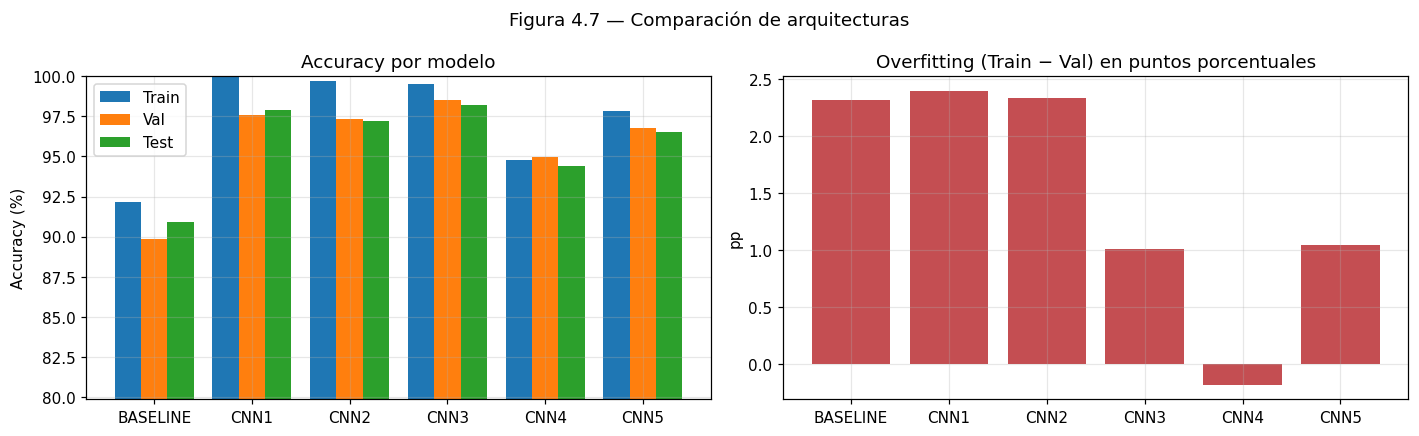

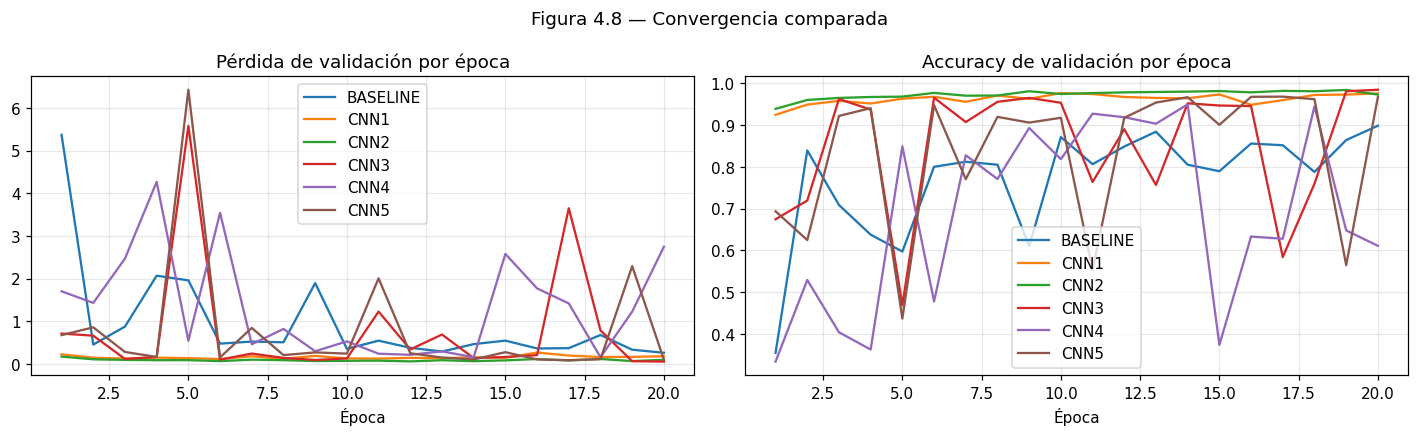

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(tabla_res)); w = 0.27
for i, (col, lab) in enumerate([("Accuracy Train (%)", "Train"), ("Accuracy Val (%)", "Val"), ("Accuracy Test (%)", "Test")]):
    axes[0].bar(x + (i - 1) * w, tabla_res[col], w, label=lab)
axes[0].set_xticks(x, tabla_res["Modelo"]); axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(max(0, tabla_res[["Accuracy Train (%)", "Accuracy Val (%)", "Accuracy Test (%)"]].values.min() - 10), 100)
axes[0].set_title("Accuracy por modelo"); axes[0].legend()
axes[1].bar(tabla_res["Modelo"], tabla_res["Overfitting (pp)"], color="#C44E52")
axes[1].set_title("Overfitting (Train − Val) en puntos porcentuales"); axes[1].set_ylabel("pp")
plt.suptitle("Figura 4.7 — Comparación de arquitecturas"); plt.tight_layout()
plt.savefig(f"{DIR_FIGURAS}/4_2_comparacion_modelos.png", dpi=200); plt.show()

# Curvas de validación de todos los modelos superpuestas
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, r in RESULTADOS.items():
    ep = np.arange(1, r["epocas"] + 1)
    axes[0].plot(ep, r["hist"]["val_loss"], label=k.upper()); axes[1].plot(ep, r["hist"]["val_accuracy"], label=k.upper())
axes[0].set_title("Pérdida de validación por época"); axes[0].set_xlabel("Época"); axes[0].legend()
axes[1].set_title("Accuracy de validación por época"); axes[1].set_xlabel("Época"); axes[1].legend()
plt.suptitle("Figura 4.8 — Convergencia comparada"); plt.tight_layout()
plt.savefig(f"{DIR_FIGURAS}/4_2_convergencia_comparada.png", dpi=200); plt.show()

**Criterio de selección:** se elige la CNN con **mayor accuracy de validación** (no de prueba, para no sesgar la evaluación final). En caso de diferencias menores a 0.5 pp, se prefiere la de menor overfitting.

$$\text{Eficiencia} = \frac{\text{val\_acc}}{\text{parámetros} / 1{,}000{,}000}$$

Esta métrica expresa cuánto accuracy de validación aporta cada millón de parámetros; un valor alto indica una arquitectura más económica en memoria y cómputo para un desempeño dado.

In [ ]:
cnns = {k: r for k, r in RESULTADOS.items() if k != "baseline"}
ordenadas = sorted(cnns.values(), key=lambda r: (-r["acc_val"], r["overfitting"]))
mejor = ordenadas[0]
# Desempate: si otra CNN está a menos de 0.5 pp y tiene menor overfitting, se prefiere
for r in ordenadas[1:]:
    if mejor["acc_val"] - r["acc_val"] < 0.005 and r["overfitting"] < mejor["overfitting"]:
        mejor = r; break
MEJOR = mejor["clave"]

tabla_sel = pd.DataFrame([{
    "Modelo": k.upper(),
    "Val Acc (%)": round(r["acc_val"] * 100, 2),
    f"Δ Val Acc vs {MEJOR.upper()} (pp)": round((r["acc_val"] - mejor["acc_val"]) * 100, 2),
    "Parámetros": r["params"],
    "Parámetros (M)": round(r["params"] / 1e6, 4),
    "Eficiencia (val_acc / M parámetros)": round(r["acc_val"] / (r["params"] / 1e6), 4),
    "Overfitting (pp)": round(r["overfitting"] * 100, 2),
} for k, r in RESULTADOS.items()])
tabla_sel.to_csv(f"{DIR_RESULTADOS}/4_3_seleccion_eficiencia.csv", index=False)
display(tabla_sel)

mas_eficiente = tabla_sel.iloc[tabla_sel["Eficiencia (val_acc / M parámetros)"].idxmax()]
print(f"Arquitectura seleccionada: {MEJOR.upper()} — val_acc = {mejor['acc_val']*100:.2f} %, "
      f"overfitting = {mejor['overfitting']*100:.2f} pp, parámetros = {mejor['params']:,}".replace(",", "."))
for k, r in cnns.items():
    if k != MEJOR:
        print(f"  {MEJOR.upper()} vs {k.upper()}: {(mejor['acc_val'] - r['acc_val'])*100:+.2f} pp de val_acc")
print(f"Modelo más eficiente: {mas_eficiente['Modelo']} "
      f"({mas_eficiente['Eficiencia (val_acc / M parámetros)']:.4f} de val_acc por millón de parámetros)")

,Modelo,Val Acc (%),Δ Val Acc vs CNN3 (pp),Parámetros,Parámetros (M),Eficiencia (val_acc / M parámetros),Overfitting (pp)
0,BASELINE,89.87,-8.62,3547523,3.5475,0.2533,2.32
1,CNN1,97.60,-0.89,4746563,4.7466,0.2056,2.40
2,CNN2,97.33,-1.16,2654883,2.6549,0.3666,2.34
3,CNN3,98.49,0.00,2656227,2.6562,0.3708,1.01
4,CNN4,94.98,-3.51,1216483,1.2165,0.7808,-0.18
5,CNN5,96.76,-1.73,2656227,2.6562,0.3643,1.05


Arquitectura seleccionada: CNN3 — val_acc = 98.49 %. overfitting = 1.01 pp. parámetros = 2.656.227
  CNN3 vs CNN1: +0.89 pp de val_acc
  CNN3 vs CNN2: +1.16 pp de val_acc
  CNN3 vs CNN4: +3.51 pp de val_acc
  CNN3 vs CNN5: +1.73 pp de val_acc
Modelo más eficiente: CNN4 (0.7808 de val_acc por millón de parámetros)


**Justificación de la selección de CNN 3:**

Se seleccionó **CNN 3** (CNN 2 + Batch Normalization) porque obtuvo el mayor accuracy de validación (98.49 %), con una ventaja de 0.89 pp sobre la segunda (CNN 1, 97.60 %). Como la diferencia supera el umbral de 0.5 pp, no fue necesario aplicar el criterio de desempate. El conjunto de prueba confirmó la elección: CNN 3 también tuvo el mejor accuracy de prueba (98.18 %), con 41 errores en 2250 imágenes.

| Modelo | Val Acc (%) | Δ vs CNN 3 (pp) | Parámetros (M) | Eficiencia | Overfitting (pp) |
|---|---|---|---|---|---|
| CNN 3 | 98.49 | — | 2.66 | 0.3708 | 1.01 |
| CNN 1 | 97.60 | −0.89 | 4.75 | 0.2056 | 2.40 |
| CNN 2 | 97.33 | −1.16 | 2.65 | 0.3666 | 2.34 |
| CNN 5 | 96.76 | −1.73 | 2.66 | 0.3643 | 1.05 |
| CNN 4 | 94.98 | −3.51 | 1.22 | 0.7808 | −0.18 |

1. **Exactitud:** mayor val_acc y mayor test_acc de todos los modelos.
2. **Generalización:** su brecha train−val (1.01 pp) es menos de la mitad que la de CNN 1 (2.40 pp) y CNN 2 (2.34 pp). Solo CNN 4 tiene una brecha menor, pero con 3.51 pp menos de validación.
3. **Eficiencia:** es la segunda más eficiente (0.3708). CNN 4 es 2.1 veces más eficiente gracias a *GlobalAveragePooling*, pero su menor exactitud no compensa esa ventaja. Frente a CNN 1, CNN 3 logra mayor exactitud con 44 % menos parámetros.
4. **Costo:** su entrenamiento tardó 3.68 min (11.03 s por época), frente a 1.14 min de CNN 1. Es un costo bajo en términos absolutos.

**Salvedad:** la validación de CNN 3 osciló fuertemente entre épocas (entre 46.9 % y 98.5 %; en la época 17 fue de 58.4 %). Su resultado final es alto porque las dos últimas épocas fueron buenas (98.1 % y 98.5 %), pero, sin restauración de la mejor época, el desempeño reportado depende de la época en que termina el entrenamiento. Por eso, en otras ejecuciones del notebook la arquitectura seleccionada cambió (ver sección 12).

### 8.2 Impacto de técnicas

Se comparan pares de modelos que **difieren únicamente en una técnica**:

- **Batch Normalization:** CNN 2 (sin BN) vs. CNN 3 (con BN), con Dropout 0.3 en ambos.
- **Dropout 0.3 vs 0.5:** CNN 3 (0.3) vs. CNN 5 (0.5), con BN en ambos.

$[ \text{Reducción de overfitting} = \text{Overfitting}_{\text{sin técnica}} - \text{Overfitting}_{\text{con técnica}} ]$

Un valor positivo indica que la técnica **redujo** la brecha entre entrenamiento y validación.

,Técnica evaluada,Modelo sin técnica,Modelo con técnica,Overfitting sin (pp),Overfitting con (pp),Reducción de overfitting (pp),Δ Val Acc (pp),Δ Test Acc (pp)
0,Batch Normalization,CNN2,CNN3,2.34,1.01,1.34,1.16,0.98
1,Dropout 0.5 (vs 0.3),CNN3,CNN5,1.01,1.05,-0.05,-1.73,-1.64


Técnica más efectiva para reducir el overfitting: Batch Normalization (+1.34 pp)


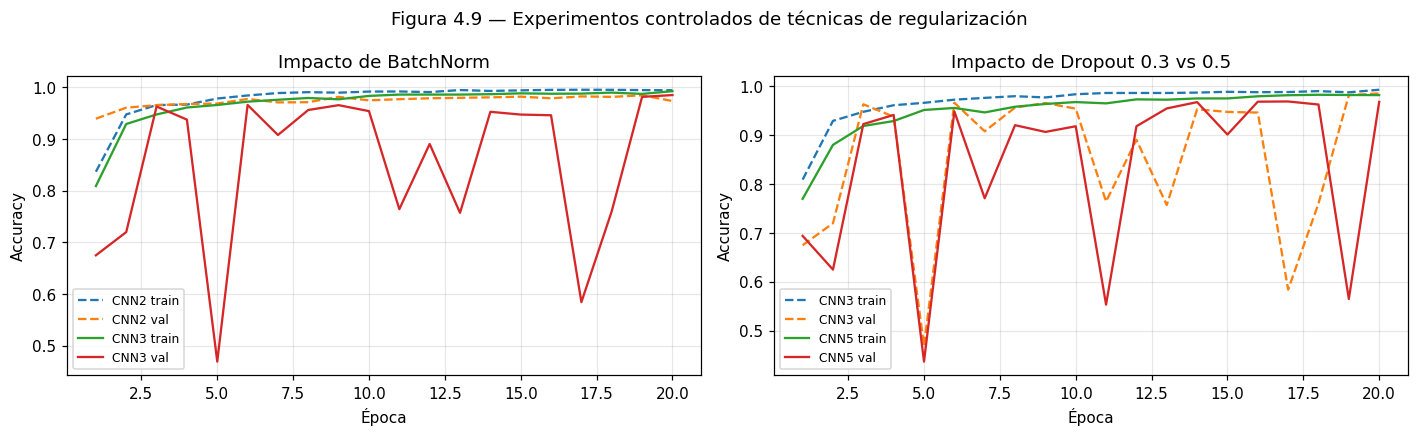

In [ ]:
def comparar(sin, con, tecnica):
    a, b = RESULTADOS[sin], RESULTADOS[con]
    return {
        "Técnica evaluada": tecnica, "Modelo sin técnica": sin.upper(), "Modelo con técnica": con.upper(),
        "Overfitting sin (pp)": round(a["overfitting"] * 100, 2),
        "Overfitting con (pp)": round(b["overfitting"] * 100, 2),
        "Reducción de overfitting (pp)": round((a["overfitting"] - b["overfitting"]) * 100, 2),
        "Δ Val Acc (pp)": round((b["acc_val"] - a["acc_val"]) * 100, 2),
        "Δ Test Acc (pp)": round((b["acc_test"] - a["acc_test"]) * 100, 2),
    }

tabla_tec = pd.DataFrame([
    comparar("cnn2", "cnn3", "Batch Normalization"),
    comparar("cnn3", "cnn5", "Dropout 0.5 (vs 0.3)"),
])
tabla_tec.to_csv(f"{DIR_RESULTADOS}/4_3_impacto_tecnicas.csv", index=False)
display(tabla_tec)
mas_efectiva = tabla_tec.loc[tabla_tec["Reducción de overfitting (pp)"].idxmax()]
print(f"Técnica más efectiva para reducir el overfitting: {mas_efectiva['Técnica evaluada']} "
      f"({mas_efectiva['Reducción de overfitting (pp)']:+.2f} pp)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (sin, con, t) in zip(axes, [("cnn2", "cnn3", "BatchNorm"), ("cnn3", "cnn5", "Dropout 0.3 vs 0.5")]):
    for k, est in ((sin, "--"), (con, "-")):
        h = RESULTADOS[k]["hist"]; ep = np.arange(1, len(h["loss"]) + 1)
        ax.plot(ep, h["accuracy"], est, label=f"{k.upper()} train"); ax.plot(ep, h["val_accuracy"], est, label=f"{k.upper()} val")
    ax.set_title(f"Impacto de {t}"); ax.set_xlabel("Época"); ax.set_ylabel("Accuracy"); ax.legend(fontsize=8)
plt.suptitle("Figura 4.9 — Experimentos controlados de técnicas de regularización"); plt.tight_layout()
plt.savefig(f"{DIR_FIGURAS}/4_3_impacto_tecnicas.png", dpi=200); plt.show()

**Interpretación:**

- **Batch Normalization (CNN 2 → CNN 3):** BN redujo el overfitting en **1.34 pp** (de 2.34 a 1.01 pp) y además mejoró la validación en 1.16 pp y la prueba en 0.98 pp. Ambos modelos ajustaron el entrenamiento casi por completo (99.68 % y 99.50 %), así que la reducción proviene de una mejor validación, no de un peor ajuste. Sin embargo, BN también volvió el entrenamiento mucho más inestable: la validación de CNN 2 se mantuvo entre 96.0 % y 98.4 % desde la segunda época, mientras que la de CNN 3 osciló entre 46.9 % y 98.5 %. Los valores máximos de validación de ambos modelos son prácticamente iguales (98.4 % y 98.5 %), por lo que parte de la ventaja de CNN 3 se debe a que su última época coincidió con uno de sus mejores valores. Esta inestabilidad se explica porque, con una tasa de aprendizaje fija de 0.001, las medias y varianzas móviles que BN usa en inferencia no alcanzan a estabilizarse mientras los pesos cambian bruscamente.
- **Dropout 0.5 vs 0.3 (CNN 3 → CNN 5):** Dropout 0.5 **no redujo** el overfitting (−0.05 pp: de 1.01 a 1.05 pp) y disminuyó la validación en 1.73 pp y la prueba en 1.64 pp. El mayor Dropout sí bajó el ajuste al entrenamiento (de 99.50 % a 97.81 %), pero la validación bajó en la misma proporción, por lo que la brecha no cambió. Además, el máximo de validación de CNN 5 en 20 épocas (96.8 %) quedó por debajo del de CNN 3 (98.5 %): con Dropout 0.5 la red converge más lento, y 20 épocas no fueron suficientes.
- **Técnica más efectiva:** **Batch Normalization**, porque redujo la brecha en 1.34 pp y al mismo tiempo mejoró la exactitud. Dropout 0.5 no aportó beneficio en esta arquitectura, cuya cabeza densa ya estaba regularizada con Dropout 0.3 y BN.

### 8.3 Análisis de errores

De la matriz de confusión del mejor modelo se identifica el **par de clases más confundidas**, sumando los errores en ambas direcciones: $( e_{ij} = CM_{ij} + CM_{ji} )$. Se muestran 3 ejemplos mal clasificados de cada una de las dos clases (6 imágenes). Si alguna dirección tiene menos de 3 errores, se completa con ejemplos correctos de esa clase con la menor confianza (los casos más cercanos a la frontera de decisión).

Modelo analizado: CNN3
Par más confundido: Sandal ↔ Shoe — 21 errores en total (Sandal→Shoe: 12, Shoe→Sandal: 9)
Todos los pares: {'Boot↔Sandal': 7, 'Boot↔Shoe': 13, 'Sandal↔Shoe': 21}


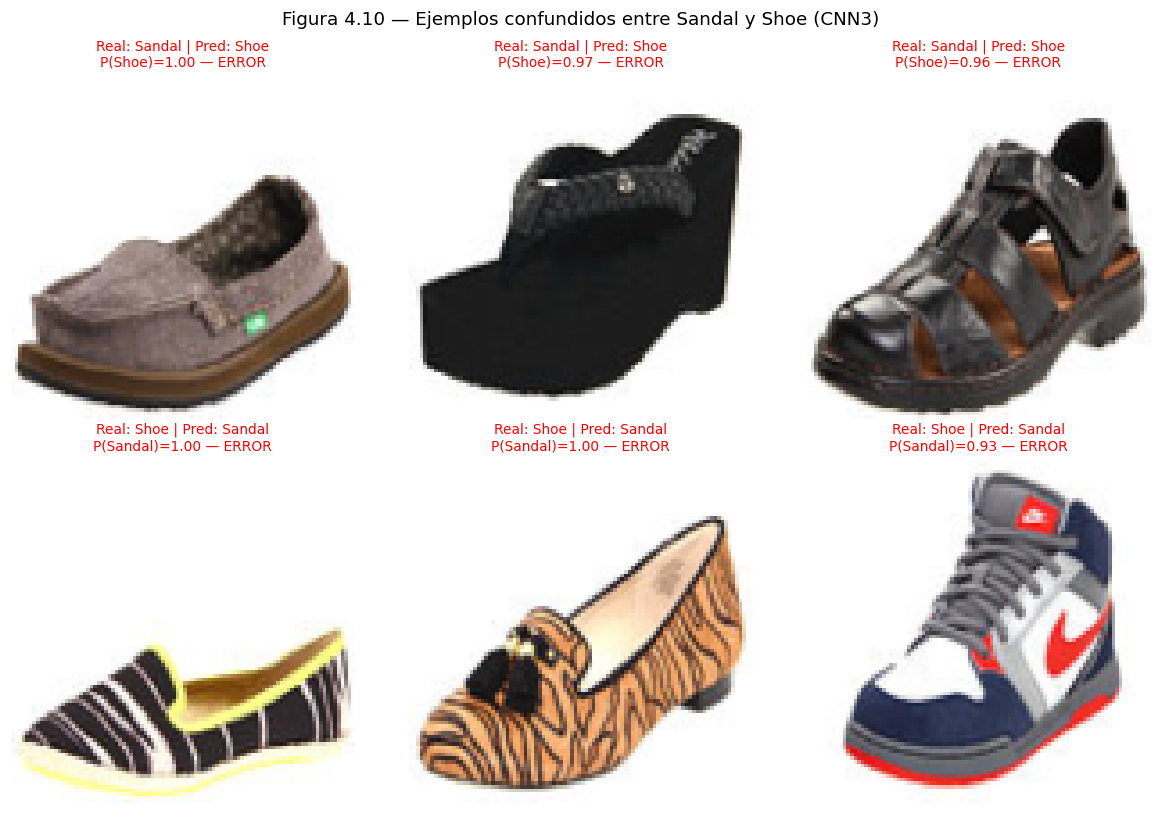

In [ ]:
mejor_modelo = {"cnn1": cnn1, "cnn2": cnn2, "cnn3": cnn3, "cnn4": cnn4, "cnn5": cnn5}[MEJOR]
cm = RESULTADOS[MEJOR]["cm"]
proba_mejor = mejor_modelo.predict(ds_test, verbose=0)
y_pred_m = proba_mejor.argmax(1)

pares = [((i, j), cm[i, j] + cm[j, i]) for i in range(NUM_CLASES) for j in range(i + 1, NUM_CLASES)]
(ci, cj), n_err = max(pares, key=lambda t: t[1])
print(f"Modelo analizado: {MEJOR.upper()}")
print(f"Par más confundido: {CLASES[ci]} ↔ {CLASES[cj]} — {n_err} errores en total "
      f"({CLASES[ci]}→{CLASES[cj]}: {cm[ci, cj]}, {CLASES[cj]}→{CLASES[ci]}: {cm[cj, ci]})")
print("Todos los pares:", {f"{CLASES[i]}↔{CLASES[j]}": int(e) for (i, j), e in pares})

def ejemplos(real, otra, k=3):
    err = np.where((y_test == real) & (y_pred_m == otra))[0]
    err = err[np.argsort(-proba_mejor[err, otra])][:k]
    sel = [(i, "ERROR") for i in err]
    if len(sel) < k:   # completar con aciertos de baja confianza
        acierto = np.where((y_test == real) & (y_pred_m == real))[0]
        acierto = acierto[np.argsort(proba_mejor[acierto, real])][:k - len(sel)]
        sel += [(i, "acierto (baja confianza)") for i in acierto]
    return sel

fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for fila, (real, otra) in enumerate([(ci, cj), (cj, ci)]):
    for col, (idx, tipo) in enumerate(ejemplos(real, otra)):
        ax = axes[fila, col]
        ax.imshow(X_test[idx]); ax.axis("off")
        ax.set_title(f"Real: {CLASES[real]} | Pred: {CLASES[y_pred_m[idx]]}\n"
                     f"P({CLASES[otra]})={proba_mejor[idx, otra]:.2f} — {tipo}", fontsize=9,
                     color="red" if tipo == "ERROR" else "black")
plt.suptitle(f"Figura 4.10 — Ejemplos confundidos entre {CLASES[ci]} y {CLASES[cj]} ({MEJOR.upper()})")
plt.tight_layout(); plt.savefig(f"{DIR_FIGURAS}/4_3_analisis_errores.png", dpi=200); plt.show()

**Interpretación de las confusiones entre clases:** el par más confundido por CNN 3 es **Sandal ↔ Shoe**, con 21 errores (12 sandalias clasificadas como zapatos y 9 zapatos clasificados como sandalias), frente a 13 errores en Boot ↔ Shoe y 7 en Boot ↔ Sandal. La Figura 4.10 muestra que la frontera entre ambas clases depende de cuánto del pie queda expuesto, y que existen productos en el límite de las dos categorías:

- **Sandalias con empeine cerrado, clasificadas como zapatos:** una sandalia tipo mocasín con la parte delantera totalmente cerrada, una sandalia de plataforma negra cuyo volumen oscuro oculta la tira, y una sandalia tipo *fisherman* con la puntera cerrada y tiras anchas. Las tres tienen silueta de zapato cerrado; el rasgo que las hace sandalias (talón descubierto o huecos entre tiras) es pequeño o queda oculto en la vista lateral.
- **Zapatos muy abiertos, clasificados como sandalias:** dos zapatos planos tipo *slip-on* y mocasín con un corte muy bajo, que dejan ver gran parte de la plantilla, igual que una sandalia. El tercer caso, un tenis de caña alta, es el menos explicable por la forma; su diseño de paneles blancos y de colores con fuerte contraste podría haber sido interpretado como tiras separadas por espacios.

Los errores se deben a la ambigüedad visual del propio dataset, más que a una falla de aprendizaje: en estos productos, la diferencia entre sandalia y zapato es una cuestión de diseño (cuánto se abre el calzado) que a 96 × 96 píxeles ocupa pocos píxeles.

### 8.4 Limitaciones: clase con peor F1-score

Se calculan manualmente, a partir de la matriz de confusión del mejor modelo, las métricas de la clase con menor F1:

$[ P = \frac{TP}{TP+FP}, \qquad R = \frac{TP}{TP+FN}, \qquad F1 = \frac{2PR}{P+R} ]$

In [ ]:
filas = []
for c in range(NUM_CLASES):
    TP = cm[c, c]; FP = cm[:, c].sum() - TP; FN = cm[c, :].sum() - TP
    P = TP / (TP + FP) if TP + FP else 0.0
    R = TP / (TP + FN) if TP + FN else 0.0
    F1 = 2 * P * R / (P + R) if P + R else 0.0
    filas.append({"Clase": CLASES[c], "TP": TP, "FP": FP, "FN": FN,
                  "Precision": round(P, 4), "Recall": round(R, 4), "F1-score": round(F1, 4)})
tabla_f1 = pd.DataFrame(filas)
tabla_f1.to_csv(f"{DIR_RESULTADOS}/4_3_metricas_por_clase.csv", index=False)
display(tabla_f1)
peor = tabla_f1.loc[tabla_f1["F1-score"].idxmin()]
print(f"Clase con peor F1-score: {peor['Clase']}")
print(f"  Precision = {peor.TP} / ({peor.TP} + {peor.FP}) = {peor.Precision:.4f}")
print(f"  Recall    = {peor.TP} / ({peor.TP} + {peor.FN}) = {peor.Recall:.4f}")
print(f"  F1        = 2·{peor.Precision:.4f}·{peor.Recall:.4f} / ({peor.Precision:.4f} + {peor.Recall:.4f}) = {peor['F1-score']:.4f}")
print("  Diagnóstico:", "predomina el bajo RECALL (la red no reconoce todos sus ejemplos)"
      if peor.Recall < peor.Precision else "predomina la baja PRECISION (otras clases se predicen como esta)")

,Clase,TP,FP,FN,Precision,Recall,F1-score
0,Boot,735,5,15,0.9932,0.9800,0.9866
1,Sandal,736,14,14,0.9813,0.9813,0.9813
2,Shoe,738,22,12,0.9711,0.9840,0.9775


Clase con peor F1-score: Shoe
  Precision = 738 / (738 + 22) = 0.9711
  Recall    = 738 / (738 + 12) = 0.9840
  F1        = 2·0.9711·0.9840 / (0.9711 + 0.9840) = 0.9775
  Diagnóstico: predomina la baja PRECISION (otras clases se predicen como esta)


**Estrategia concreta de mejora para la clase *Shoe*:**

La clase *Shoe* tiene el peor F1 (0.9775), aunque la diferencia con las demás es pequeña (0.9866 en *Boot* y 0.9813 en *Sandal*). Su problema es de **precisión** (0.9711, frente a un recall de 0.9840): el modelo predice *Shoe* en 22 imágenes que no lo son, de las cuales 12 son sandalias y 10 son botas. Es decir, *Shoe* funciona como la clase por defecto cuando el calzado tiene una silueta cerrada y ambigua. La estrategia propuesta ataca esos falsos positivos:

1. **Aumentar la resolución de entrada a 128 × 128 o usar la resolución nativa (136 × 102):** los rasgos que separan una sandalia cerrada o un botín bajo de un zapato (talón descubierto, huecos entre tiras, altura de la caña) ocupan pocos píxeles a 96 × 96. Preservar la relación de aspecto original también evita deformar la silueta.
2. **Transfer learning con *fine-tuning* (MobileNetV2 o EfficientNetB0 preentrenados en ImageNet):** estos modelos ya distinguen sandalias, botas y calzado deportivo entre sus 1000 clases, y aportan descriptores de textura y material que una red entrenada desde cero con 10 498 imágenes no alcanza a aprender.
3. **Entrenamiento enfocado en los ejemplos difíciles:** usar *focal loss*, que asigna mayor peso a los ejemplos mal clasificados con alta confianza, para que el modelo aprenda la frontera entre *Shoe* y las sandalias cerradas y los botines bajos, en lugar de recurrir a *Shoe* cuando la silueta es ambigua.

## 9. Comparación final: MLP vs. mejor CNN (4.4)

$[ \text{Mejora absoluta} = \text{CNN} - \text{MLP}, \qquad \text{Mejora relativa (\%)} = \frac{\text{CNN} - \text{MLP}}{\text{MLP}} \times 100 ]$

In [ ]:
b, c = RESULTADOS["baseline"], RESULTADOS[MEJOR]
def fila(nombre, vm, vc, mejora=True, dec=4):
    if dec == 0:
        vm, vc = int(vm), int(vc)
    return {"Métrica": nombre, "MLP Baseline": round(vm, dec), f"Mejor CNN ({MEJOR.upper()})": round(vc, dec),
            "Mejora Absoluta": round(vc - vm, dec) if mejora else "N/A",
            "Mejora Relativa (%)": round((vc - vm) / vm * 100, 2) if mejora and vm else "N/A"}

tabla_final = pd.DataFrame([
    fila("Test Accuracy", b["acc_test"], c["acc_test"]),
    fila("Precision (macro)", b["precision"], c["precision"]),
    fila("Recall (macro)", b["recall"], c["recall"]),
    fila("F1-Score (macro)", b["f1"], c["f1"]),
    fila("Parámetros totales", b["params"], c["params"], mejora=False, dec=0),
    fila("Tiempo entrenamiento (min)", b["t_total"] / 60, c["t_total"] / 60, mejora=False, dec=2),
], dtype=object)
tabla_final.to_csv(f"{DIR_RESULTADOS}/4_4_mlp_vs_cnn.csv", index=False)
tabla_final

,Métrica,MLP Baseline,Mejor CNN (CNN3),Mejora Absoluta,Mejora Relativa (%)
0,Test Accuracy,0.9089,0.9818,0.0729,8.02
1,Precision (macro),0.9088,0.9819,0.0731,8.05
2,Recall (macro),0.9089,0.9818,0.0729,8.02
3,F1-Score (macro),0.9085,0.9818,0.0733,8.06
4,Parámetros totales,3547523,2656227,N/A,N/A
5,Tiempo entrenamiento (min),0.42,3.68,N/A,N/A


**Conclusión:** la CNN seleccionada (CNN 3) alcanzó un accuracy de prueba de 98.18 %, frente a 90.89 % del MLP: una mejora absoluta de 7.29 pp y relativa de 8.02 %, con un F1 macro que pasó de 0.909 a 0.982. En términos prácticos, los errores en prueba bajaron de 205 a 41 de 2250 imágenes, una reducción del 80 %. Esta mejora se obtuvo con 25 % menos parámetros que el MLP (2.66 M frente a 3.55 M), porque las convoluciones comparten pesos y capturan la forma del calzado (caña, correas, aberturas) sin importar su posición. El costo fue un tiempo de entrenamiento 8.7 veces mayor (3.68 frente a 0.42 min). Para este dataset, el aumento de complejidad se justifica: el costo adicional es de pocos minutos y se paga una sola vez, mientras que el modelo resultante es más pequeño y comete cinco veces menos errores.

## 10. Exportación de entregables

Se genera un archivo `.zip` con:
- `modelos/` → `APELLIDOS_baseline.h5`, `APELLIDOS_cnn1.h5` … `APELLIDOS_cnn5.h5` y `clases.json` (orden de clases y tamaño de entrada, necesario para usar los modelos).
- `figuras/` → todas las figuras en PNG a 200 dpi, listas para el informe.
- `resultados/` → todas las tablas en CSV.

Opcionalmente se copian a Google Drive (`MyDrive/IC_Punto4/`). Si se usa Drive, la celda solicitará autorización.

In [ ]:
with open(f"{DIR_MODELOS}/clases.json", "w") as f:
    json.dump({"clases": CLASES, "img_size": list(IMG_SIZE), "entrada": "RGB uint8 0-255 (la normalización está dentro del modelo)",
               "mejor_modelo": f"{APELLIDOS}_{MEJOR}.h5"}, f, ensure_ascii=False, indent=2)

# Resumen de todos los experimentos en JSON (sin arrays grandes)
resumen = {k: {kk: (float(vv) if isinstance(vv, (np.floating, float)) else vv)
               for kk, vv in r.items() if kk not in ("cm", "y_pred", "hist")} for k, r in RESULTADOS.items()}
with open(f"{DIR_RESULTADOS}/resumen_experimentos.json", "w") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2, default=int)

nombre_zip = f"{APELLIDOS}_punto4_entregables"
import zipfile
with zipfile.ZipFile(f"{nombre_zip}.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for carpeta in (DIR_MODELOS, DIR_FIGURAS, DIR_RESULTADOS):
        for ruta in glob.glob(f"{carpeta}/*"):
            z.write(ruta)
print(f"Archivo generado: {nombre_zip}.zip ({os.path.getsize(nombre_zip + '.zip')/1024**2:.1f} MB)")
for ruta in sorted(glob.glob(f"{DIR_MODELOS}/*")):
    print(f"  {ruta}  ({os.path.getsize(ruta)/1024**2:.1f} MB)")

Archivo generado: Silva_Leon_Gomez_Tobar_punto4_entregables.zip (127.9 MB)
  modelos/Gomez_Tobar_baseline.h5  (13.6 MB)
  modelos/Gomez_Tobar_cnn1.h5  (18.1 MB)
  modelos/Gomez_Tobar_cnn2.h5  (10.2 MB)
  modelos/Gomez_Tobar_cnn3.h5  (10.2 MB)
  modelos/Gomez_Tobar_cnn4.h5  (4.7 MB)
  modelos/Gomez_Tobar_cnn5.h5  (10.2 MB)
  modelos/Silva_Leon_Gomez_Tobar_baseline.h5  (13.6 MB)
  modelos/Silva_Leon_Gomez_Tobar_cnn1.h5  (18.1 MB)
  modelos/Silva_Leon_Gomez_Tobar_cnn2.h5  (10.2 MB)
  modelos/Silva_Leon_Gomez_Tobar_cnn3.h5  (10.2 MB)
  modelos/Silva_Leon_Gomez_Tobar_cnn4.h5  (4.7 MB)
  modelos/Silva_Leon_Gomez_Tobar_cnn5.h5  (10.2 MB)
  modelos/clases.json  (0.0 MB)


In [ ]:
GUARDAR_EN_DRIVE = False   # True: copia los entregables a Google Drive (MyDrive/IC_Punto4)
DESCARGAR_ZIP    = True    # descarga automática del .zip en el navegador

if "google.colab" in sys.modules:
    if GUARDAR_EN_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        destino = "/content/drive/MyDrive/IC_Punto4"
        os.makedirs(destino, exist_ok=True)
        shutil.copy(f"{nombre_zip}.zip", destino)
        shutil.copytree(DIR_MODELOS, f"{destino}/{DIR_MODELOS}", dirs_exist_ok=True)
        print("Copiado en", destino)
    if DESCARGAR_ZIP:
        from google.colab import files
        files.download(f"{nombre_zip}.zip")
else:
    print("Ejecución fuera de Colab: los archivos quedan en", os.getcwd())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Verificación de los modelos entregados

Esta sección demuestra que los archivos `.h5` son **cargables y funcionales**, tal como exige la rúbrica. Se cargan desde disco (sin usar los objetos que están en memoria), se evalúan sobre el conjunto de prueba y se comprueba que el accuracy coincide con el registrado durante el entrenamiento. Por último, se clasifican imágenes de prueba aleatorias con el mejor modelo.

> Para verificar modelos descargados en otra sesión de Colab: ejecutar las secciones 0 a 3 (análisis y partición, sin entrenar; reconstruyen el mismo conjunto de prueba con la misma semilla), subir los `.h5` y `clases.json` a la carpeta `modelos/` y ejecutar esta sección.

In [ ]:
sello("Verificación de modelos .h5 cargados desde disco")
# Valores de referencia: los de esta sesión o, en una sesión nueva, los del resumen exportado (si se subió)
if "RESULTADOS" in globals() and RESULTADOS:
    REFERENCIA = RESULTADOS
elif os.path.exists(f"{DIR_RESULTADOS}/resumen_experimentos.json"):
    with open(f"{DIR_RESULTADOS}/resumen_experimentos.json") as f:
        REFERENCIA = json.load(f)
else:
    REFERENCIA = {}
filas = []
for ruta in sorted(glob.glob(f"{DIR_MODELOS}/{APELLIDOS}_*.h5")):
    clave = os.path.basename(ruta).replace(f"{APELLIDOS}_", "").replace(".h5", "")
    m = keras.models.load_model(ruta, compile=False)
    pred = m.predict(ds_test, verbose=0).argmax(1)
    acc = accuracy_score(y_test, pred)
    ref = REFERENCIA.get(clave, {}).get("acc_test", np.nan)
    filas.append({"Archivo": os.path.basename(ruta), "Parámetros": m.count_params(),
                  "Test Acc recargado (%)": round(acc * 100, 2), "Test Acc registrado (%)": round(ref * 100, 2),
                  "Coincide": bool(abs(acc - ref) < 1e-3) if not np.isnan(ref) else "N/D"})
tabla_verif = pd.DataFrame(filas)
display(tabla_verif)

  Verificación de modelos .h5 cargados desde disco
  Fecha/hora : 2026-11-20 21:36:35 (America/Bogota)
  Usuario SO : root   |   Integrantes: Cristian Gomez, Juan Leon, Miguel Silva, Alexis Tobar
  Máquina    : 14793758e7a8   |   GPU: True


,Archivo,Parámetros,Test Acc recargado (%),Test Acc registrado (%),Coincide
0,Silva_Leon_Gomez_Tobar_baseline.h5,3547523,90.89,90.89,True
1,Silva_Leon_Gomez_Tobar_cnn1.h5,4746563,97.87,97.87,True
2,Silva_Leon_Gomez_Tobar_cnn2.h5,2654883,97.20,97.20,True
3,Silva_Leon_Gomez_Tobar_cnn3.h5,2656227,98.18,98.18,True
4,Silva_Leon_Gomez_Tobar_cnn4.h5,1216483,94.40,94.40,True
5,Silva_Leon_Gomez_Tobar_cnn5.h5,2656227,96.53,96.53,True


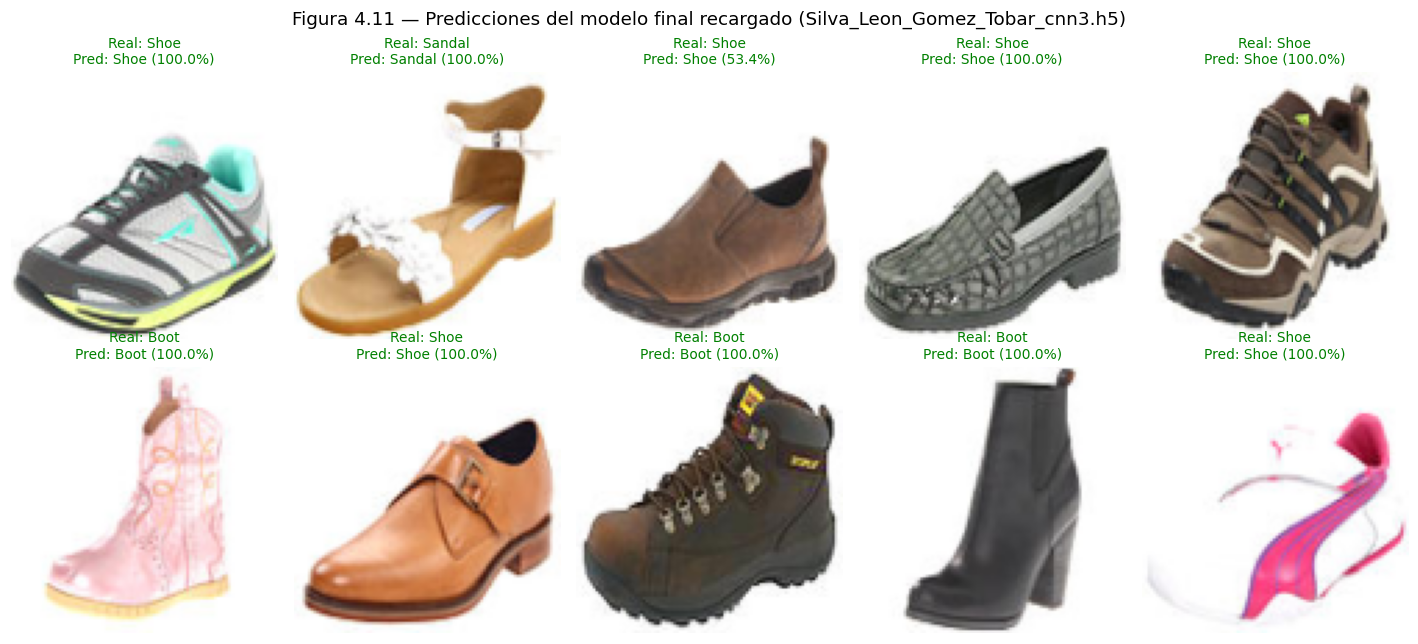

In [ ]:
if "MEJOR" not in globals():   # sesión nueva: se lee el mejor modelo desde clases.json
    with open(f"{DIR_MODELOS}/clases.json") as f:
        MEJOR = json.load(f)["mejor_modelo"].replace(f"{APELLIDOS}_", "").replace(".h5", "")
modelo_final = keras.models.load_model(f"{DIR_MODELOS}/{APELLIDOS}_{MEJOR}.h5", compile=False)
rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(X_test), 10, replace=False)
proba = modelo_final.predict(X_test[idx].astype("float32"), verbose=0)
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for a, i, p in zip(axes.ravel(), idx, proba):
    pred = p.argmax(); ok_ = pred == y_test[i]
    a.imshow(X_test[i]); a.axis("off")
    a.set_title(f"Real: {CLASES[y_test[i]]}\nPred: {CLASES[pred]} ({p[pred]:.1%})", color="green" if ok_ else "red", fontsize=9)
plt.suptitle(f"Figura 4.11 — Predicciones del modelo final recargado ({APELLIDOS}_{MEJOR}.h5)")
plt.tight_layout(); plt.savefig(f"{DIR_FIGURAS}/4_verificacion_predicciones.png", dpi=200); plt.show()

## 12. Limitaciones y recomendaciones técnicas

- **Resolución de entrada:** el redimensionamiento a 96×96 sacrifica detalles finos (correas, cordones, altura de la caña), que son justamente los que separan las clases más confundidas.
- **Sesgo del dominio:** las imágenes del dataset son fotografías de catálogo (fondo claro, vista lateral). El desempeño probablemente disminuirá con fotos reales en contextos variados (fondos complejos, ángulos superiores).
- **Inestabilidad de los modelos con Batch Normalization:** la validación de CNN 3, CNN 4 y CNN 5 osciló fuertemente entre épocas (por ejemplo, entre 46.9 % y 98.5 % en CNN 3, y entre 43.7 % y 96.8 % en CNN 5). CNN 3 y CNN 5 no usan Early Stopping, por lo que su desempeño reportado corresponde a la época 20 y no a la mejor. En CNN 4, la oscilación hizo que Early Stopping detuviera el entrenamiento en la época 20, antes de que la reducción de la tasa de aprendizaje estabilizara el modelo. Un *callback* `ModelCheckpoint` con `save_best_only=True` en todos los modelos y una paciencia mayor en CNN 4 harían los resultados más estables.
- **Variabilidad entre ejecuciones:** en ejecuciones sucesivas del notebook, el número de épocas de CNN 4 y la arquitectura seleccionada cambiaron, porque las diferencias entre las mejores CNN son de alrededor de 1 pp y dependen de la época en que termina el entrenamiento de los modelos inestables. El cómputo en GPU no es completamente determinista, aun con la semilla fija.
- **Una sola corrida por configuración:** por lo anterior, una evaluación más rigurosa usaría validación cruzada *k-fold* o varias semillas, reportando la media y la desviación estándar de cada arquitectura.